#Import Libraries

In [1]:
import pandas as pd
import numpy as np
from google.colab import files
import matplotlib.pyplot as plt
import seaborn as sns
import io

# Upload the data file

In [2]:
data=files.upload()

Saving Heart_disease_cleveland_new.csv to Heart_disease_cleveland_new.csv


#Read the Dataset

In [3]:
df=pd.read_csv(io.BytesIO(data['Heart_disease_cleveland_new.csv']), encoding='latin1')
df.head()

,ï»¿age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,0,145,233,1,2,150,0,2.3,2,0,2,0
1,67,1,3,160,286,0,2,108,1,1.5,1,3,1,1
2,67,1,3,120,229,0,2,129,1,2.6,1,2,3,1
3,37,1,2,130,250,0,0,187,0,3.5,2,0,1,0
4,41,0,1,130,204,0,2,172,0,1.4,0,0,1,0


# Columns and rows in the dataset

In [4]:
df.shape

(303, 14)

# Checking data type on each column

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   ï»¿age    303 non-null    int64  
 1   sex       303 non-null    int64  
 2   cp        303 non-null    int64  
 3   trestbps  303 non-null    int64  
 4   chol      303 non-null    int64  
 5   fbs       303 non-null    int64  
 6   restecg   303 non-null    int64  
 7   thalach   303 non-null    int64  
 8   exang     303 non-null    int64  
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    int64  
 11  ca        303 non-null    int64  
 12  thal      303 non-null    int64  
 13  target    303 non-null    int64  
dtypes: float64(1), int64(13)
memory usage: 33.3 KB


# Check for the missing values

In [6]:
df.isnull().sum()

,0
ï»¿age,0
sex,0
cp,0
trestbps,0
chol,0
fbs,0
restecg,0
thalach,0
exang,0
oldpeak,0


# Detect duplicated values

In [7]:
df.duplicated().sum()

np.int64(0)

# Get Box plot for each column to idenvisualize any anomalies

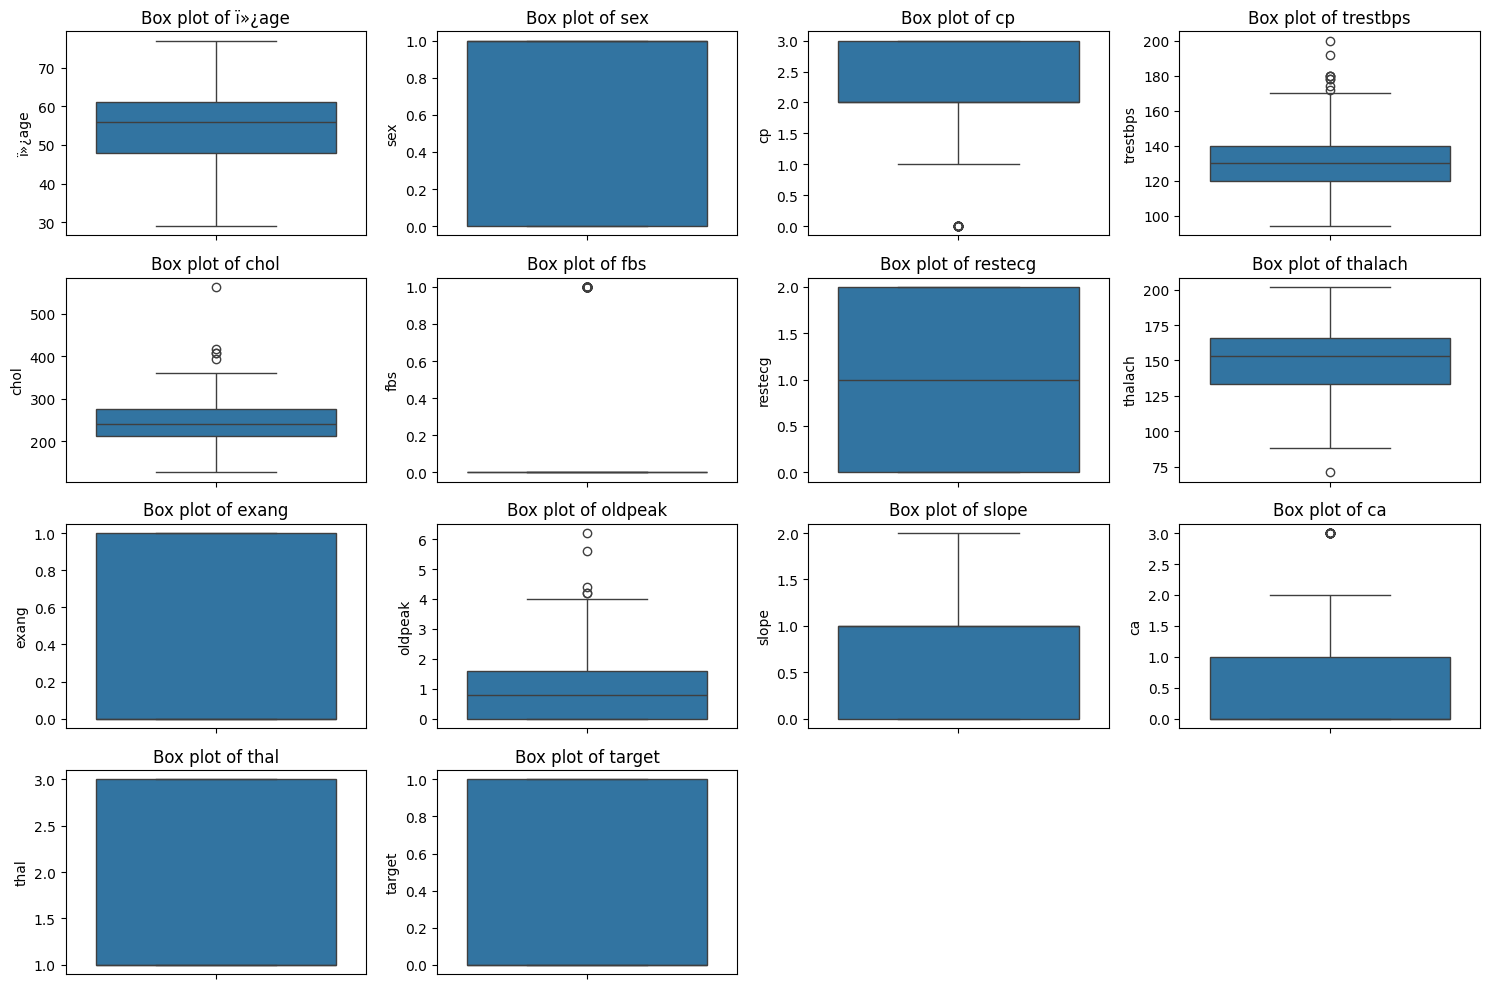

In [8]:
# Step 1: Select only numeric columns (int64 and float64)
numeric_cols = df.select_dtypes(include=['int64', 'float64']).columns

# Step 2: Create a big figure (15x10 inches)
plt.figure(figsize=(15, 10))

# Step 3: Loop through each numeric column and plot a boxplot
for i, col in enumerate(numeric_cols):
    plt.subplot(4, 4, i + 1)          # Create a grid of 4 rows x 4 columns
    sns.boxplot(y=df[col])            # Draw boxplot for current column
    plt.title(f'Box plot of {col}')   # Set title with column name

# Step 4: Adjust layout so plots don't overlap
plt.tight_layout()

# Step 5: Display the plots
plt.show()

# Detect the outliers

In [9]:
# Function to detect outliers using IQR method
def detect_outliers_iqr(df, column):
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Get rows that are outliers
    outliers = df[(df[column] < lower_bound) | (df[column] > upper_bound)]

    return outliers, lower_bound, upper_bound


# List of columns to check for outliers
outlier_columns = ['trestbps', 'chol', 'thalach', 'oldpeak']

# Check outliers in each column
for col in outlier_columns:
    outliers, lower, upper = detect_outliers_iqr(df, col)

    print(f"\n{'='*60}")
    print(f"Outliers in '{col}' (using IQR method)")
    print(f"Lower Bound: {lower:.2f} | Upper Bound: {upper:.2f}")
    print(f"{'='*60}")

    if not outliers.empty:
        print(f"Total outliers detected: {len(outliers)}\n")
        # Display important columns for easy understanding
        display(outliers[['ï»¿age', 'sex', col]])
    else:
        print("No outliers detected in this column.")


Outliers in 'trestbps' (using IQR method)
Lower Bound: 90.00 | Upper Bound: 170.00
Total outliers detected: 9



,ï»¿age,sex,trestbps
14,52,1,172
83,68,1,180
126,56,0,200
172,59,0,174
183,59,1,178
188,54,1,192
201,64,0,180
213,66,0,178
231,55,0,180



Outliers in 'chol' (using IQR method)
Lower Bound: 115.00 | Upper Bound: 371.00
Total outliers detected: 5



,ï»¿age,sex,chol
48,65,0,417
121,63,0,407
152,67,0,564
173,62,0,394
181,56,0,409



Outliers in 'thalach' (using IQR method)
Lower Bound: 84.75 | Upper Bound: 214.75
Total outliers detected: 1



,ï»¿age,sex,thalach
245,67,1,71



Outliers in 'oldpeak' (using IQR method)
Lower Bound: -2.40 | Upper Bound: 4.00
Total outliers detected: 5



,ï»¿age,sex,oldpeak
91,62,0,6.2
123,55,1,5.6
183,59,1,4.2
191,51,1,4.2
285,58,1,4.4


# Remove the Outliers

In [10]:
# Function to detect outliers using IQR method (redefined for clarity, though already exists)
def detect_outliers_iqr(df, column):
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Get indices of rows that are outliers
    outlier_indices = df[(df[column] < lower_bound) | (df[column] > upper_bound)].index
    return outlier_indices

# List of columns to check for outliers (same as before)
outlier_columns = ['trestbps', 'chol', 'thalach', 'oldpeak']

# Collect all outlier indices
all_outlier_indices = pd.Index([])
for col in outlier_columns:
    indices = detect_outliers_iqr(df, col)
    all_outlier_indices = all_outlier_indices.union(indices)

print(f"Total number of rows before outlier removal: {len(df)}")
print(f"Number of outlier rows to be removed: {len(all_outlier_indices)}")

# Remove the outlier rows from the DataFrame
df_cleaned = df.drop(all_outlier_indices)

print(f"Total number of rows after outlier removal: {len(df_cleaned)}")
display(df_cleaned.head())

Total number of rows before outlier removal: 303
Number of outlier rows to be removed: 19
Total number of rows after outlier removal: 284


,ï»¿age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,0,145,233,1,2,150,0,2.3,2,0,2,0
1,67,1,3,160,286,0,2,108,1,1.5,1,3,1,1
2,67,1,3,120,229,0,2,129,1,2.6,1,2,3,1
3,37,1,2,130,250,0,0,187,0,3.5,2,0,1,0
4,41,0,1,130,204,0,2,172,0,1.4,0,0,1,0


# Check again for Outliers to Confirm There was not any Left

In [11]:
# Re-check for outliers in df_cleaned
print("Checking for outliers in df_cleaned after removal:\n")

# Function to detect outliers using IQR method - copied here to ensure correct definition is used
def detect_outliers_iqr(df, column):
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Get rows that are outliers
    outliers = df[(df[column] < lower_bound) | (df[column] > upper_bound)]

    return outliers, lower_bound, upper_bound

# List of columns to check for outliers (same as before)
outlier_columns = ['trestbps', 'chol', 'thalach', 'oldpeak']

for col in outlier_columns:
    # Using the previously defined detect_outliers_iqr function
    outliers, lower, upper = detect_outliers_iqr(df_cleaned, col)

    print(f"\n{'='*60}")
    print(f"Outliers in '{col}' (using IQR method) in df_cleaned")
    print(f"Lower Bound: {lower:.2f} | Upper Bound: {upper:.2f}")
    print(f"{'='*60}")

    if not outliers.empty:
        print(f"Total outliers detected: {len(outliers)}\n")
        display(outliers[['ï»¿age', 'sex', col]])
    else:
        print("No outliers detected in this column.")

Checking for outliers in df_cleaned after removal:


Outliers in 'trestbps' (using IQR method) in df_cleaned
Lower Bound: 90.00 | Upper Bound: 170.00
No outliers detected in this column.

Outliers in 'chol' (using IQR method) in df_cleaned
Lower Bound: 120.38 | Upper Bound: 361.38
No outliers detected in this column.

Outliers in 'thalach' (using IQR method) in df_cleaned
Lower Bound: 82.38 | Upper Bound: 219.38
No outliers detected in this column.

Outliers in 'oldpeak' (using IQR method) in df_cleaned
Lower Bound: -2.40 | Upper Bound: 4.00
No outliers detected in this column.


# Encode categorical variables


In [12]:
from sklearn.preprocessing import OneHotEncoder

# Identify categorical columns to encode
# Based on df.info() and problem description, these columns are likely categorical
categorical_cols = ['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'ca', 'thal']

# Apply one-hot encoding using pandas get_dummies
# This creates new columns for each category and drops the original categorical columns
df_encoded = pd.get_dummies(df_cleaned, columns=categorical_cols, drop_first=False)

print(f"Original DataFrame shape: {df_cleaned.shape}")
print(f"Encoded DataFrame shape: {df_encoded.shape}")

display(df_encoded.head())

Original DataFrame shape: (284, 14)
Encoded DataFrame shape: (284, 29)


,ï»¿age,trestbps,chol,thalach,oldpeak,target,sex_0,sex_1,cp_0,cp_1,...,slope_0,slope_1,slope_2,ca_0,ca_1,ca_2,ca_3,thal_1,thal_2,thal_3
0,63,145,233,150,2.3,0,False,True,True,False,...,False,False,True,True,False,False,False,False,True,False
1,67,160,286,108,1.5,1,False,True,False,False,...,False,True,False,False,False,False,True,True,False,False
2,67,120,229,129,2.6,1,False,True,False,False,...,False,True,False,False,False,True,False,False,False,True
3,37,130,250,187,3.5,0,False,True,False,False,...,False,False,True,True,False,False,False,True,False,False
4,41,130,204,172,1.4,0,True,False,False,True,...,True,False,False,True,False,False,False,True,False,False


# Identify Categorical Columns

In [13]:
# Display the list of categorical variables that were encoded
print("Categorical variables that were encoded:")
print(categorical_cols)

Categorical variables that were encoded:
['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'ca', 'thal']


# Standardize numeric features

In [14]:
from sklearn.preprocessing import StandardScaler

# Identify numerical columns that need scaling
# These are the columns from df_encoded that are not one-hot encoded features or the target variable.
# We can find them by excluding boolean columns (from get_dummies) and the target.

# First, identify the non-boolean, non-target columns
# The original numerical columns before encoding were: 'age', 'trestbps', 'chol', 'thalach', 'oldpeak'
# The target column is 'target'.

# Get columns that are not boolean (created by get_dummies) and not the 'target' column
features_to_scale = df_encoded.select_dtypes(include=['int64', 'float64']).columns.tolist()
if 'target' in features_to_scale:
    features_to_scale.remove('target')

print(f"Features to be scaled: {features_to_scale}")

# Initialize the StandardScaler
scaler = StandardScaler()

# Apply the scaler to the selected features
df_encoded[features_to_scale] = scaler.fit_transform(df_encoded[features_to_scale])

print("\nDataFrame after standardizing numerical features:")
display(df_encoded.head())

Features to be scaled: ['ï»¿age', 'trestbps', 'chol', 'thalach', 'oldpeak']

DataFrame after standardizing numerical features:


,ï»¿age,trestbps,chol,thalach,oldpeak,target,sex_0,sex_1,cp_0,cp_1,...,slope_0,slope_1,slope_2,ca_0,ca_1,ca_2,ca_3,thal_1,thal_2,thal_3
0,0.980969,0.973671,-0.213548,0.000000,1.319305,0,False,True,True,False,...,False,False,True,True,False,False,False,False,True,False
1,1.420393,1.946200,0.973426,-1.856679,0.538310,1,False,True,False,False,...,False,True,False,False,False,False,True,True,False,False
2,1.420393,-0.647211,-0.303131,-0.928339,1.612179,1,False,True,False,False,...,False,True,False,False,False,True,False,False,False,True
3,-1.875291,0.001141,0.167180,1.635646,2.490799,0,False,True,False,False,...,False,False,True,True,False,False,False,True,False,False
4,-1.435866,0.001141,-0.863025,0.972546,0.440685,0,True,False,False,True,...,True,False,False,True,False,False,False,True,False,False


# Identify the Numerical Columns

In [15]:
# Identify numerical columns
numerical_cols = df_encoded.select_dtypes(include=['int64', 'float64']).columns.tolist()

print("Numerical columns:")
print(numerical_cols)

Numerical columns:
['ï»¿age', 'trestbps', 'chol', 'thalach', 'oldpeak', 'target']


# Summary statistics (mean, std, etc.)

In [16]:
# Get summary statistics for the DataFrame
display(df_encoded.describe())

,ï»¿age,trestbps,chol,thalach,oldpeak,target
count,2.840000e+02,2.840000e+02,2.840000e+02,2.840000e+02,2.840000e+02,284.000000
mean,3.408854e-16,-6.098408e-17,5.003822e-17,1.250956e-17,6.254778e-17,0.443662
std,1.001765e+00,1.001765e+00,1.001765e+00,1.001765e+00,1.001765e+00,0.497693
min,-2.754140e+00,-2.332929e+00,-2.609893e+00,-2.740812e+00,-9.260576e-01,0.000000
25%,-7.767292e-01,-6.472114e-01,-7.118535e-01,-7.183579e-01,-9.260576e-01,0.000000
50%,1.021198e-01,1.141466e-03,-6.797582e-02,1.326199e-01,-3.403107e-01,0.000000
75%,6.514004e-01,6.494943e-01,6.374902e-01,7.957195e-01,6.359341e-01,1.000000
max,2.518955e+00,2.594553e+00,2.630712e+00,2.298745e+00,2.978922e+00,1.000000


# Descriptive Analysis

## Univariate Analysis = One at a time (Need to be Categorical)

### target (Heart Disease Presence) = Dependent Variable

*   **0**: No heart disease
*   **1**: Heart disease present

In [17]:
round(df.target.value_counts(normalize=True), 3)

,proportion
target,
0,0.541
1,0.459


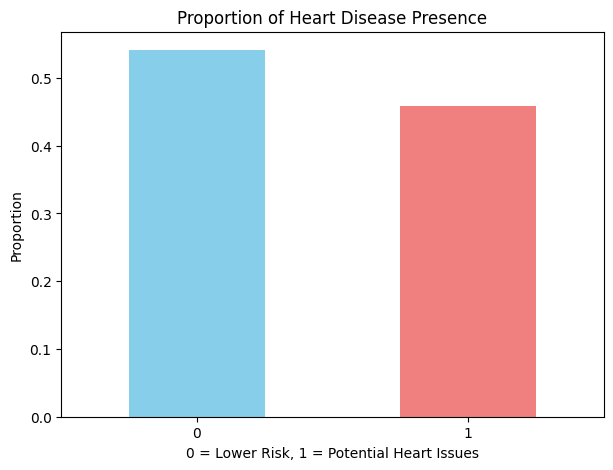

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns

# Create the bar plot for the 'target' variable
plt.figure(figsize=(7, 5))
df['target'].value_counts(normalize=True).plot(
    kind='bar',
    title='Proportion of Heart Disease Presence',
    ylabel='Proportion',
    xlabel='0 = Lower Risk, 1 = Potential Heart Issues',
    rot=0, # Keep x-axis labels horizontal
    color=['skyblue', 'lightcoral']
)
plt.show()

### Independent variables ‘Qualitative’


### Sex

*   **0**: Female
*   **1**: Male

In [19]:
round(df.sex.value_counts(normalize=True), 3)

,proportion
sex,
1,0.68
0,0.32


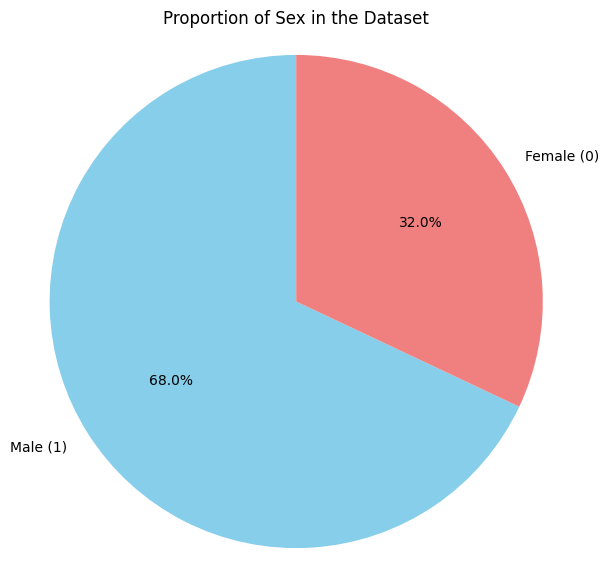

In [20]:
import matplotlib.pyplot as plt

# Calculate the value counts for the 'sex' column
sex_counts = df['sex'].value_counts(normalize=True)

# Define labels and colors
labels = ['Male (1)', 'Female (0)']
colors = ['skyblue', 'lightcoral']

# Create the pie chart
plt.figure(figsize=(7, 7))
plt.pie(sex_counts, labels=labels, colors=colors, autopct='%1.1f%%', startangle=90)
plt.title('Proportion of Sex in the Dataset')
plt.axis('equal') # Equal aspect ratio ensures that pie is drawn as a circle.
plt.show()

### cp (Chest pain type)



*   0 (Typical Angina) = Strong sign of heart disease
*   1 (Atypical Angina) = Possible but less clear
*   2 (Non-anginal Pain) = Usually not heart-related
*   3 (Asymptomatic) = No pain, but disease may still exis

In [21]:
round(df.cp.value_counts(normalize=True), 3)

,proportion
cp,
3,0.475
2,0.284
1,0.165
0,0.076


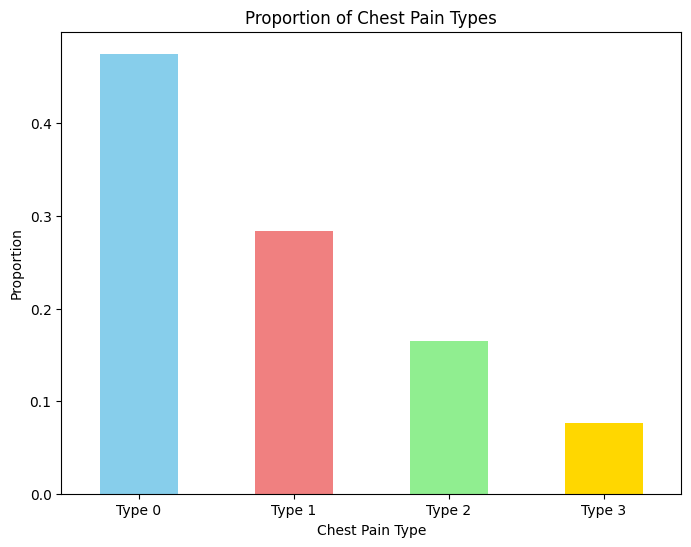

In [22]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 6))
df['cp'].value_counts(normalize=True).plot(
    kind='bar',
    title='Proportion of Chest Pain Types',
    ylabel='Proportion',
    xlabel='Chest Pain Type',
    rot=0, # Keep x-axis labels horizontal
    color=['skyblue', 'lightcoral', 'lightgreen', 'gold']
)
plt.xticks(ticks=[0, 1, 2, 3], labels=['Type 0', 'Type 1', 'Type 2', 'Type 3'])
plt.show()

### fbs = Fasting blood sugar



*   0 = false (Blood sugar ≤ 120 mg/dl (Normal))
*   1 = true  (Blood sugar > 120 mg/dl (High))

In [23]:
round(df.fbs.value_counts(normalize=True), 3)

,proportion
fbs,
0,0.851
1,0.149


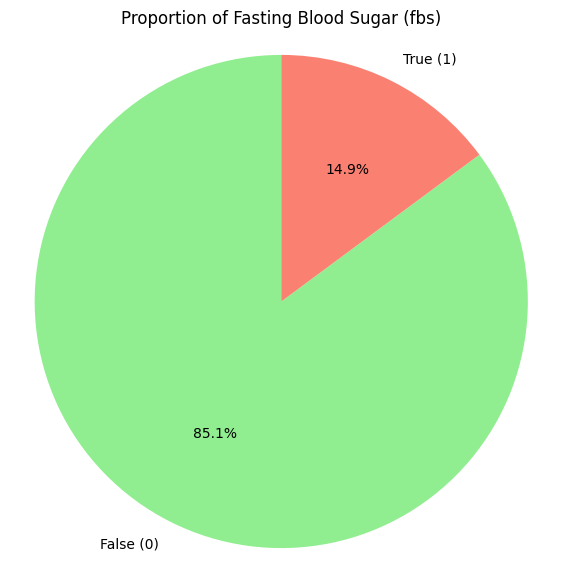

In [24]:
import matplotlib.pyplot as plt

# Calculate the value counts for the 'fbs' column
fbs_counts = df['fbs'].value_counts(normalize=True)

# Define labels and colors
labels = ['False (0)', 'True (1)']
colors = ['lightgreen', 'salmon']

# Create the pie chart
plt.figure(figsize=(7, 7))
plt.pie(fbs_counts, labels=labels, colors=colors, autopct='%1.1f%%', startangle=90)
plt.title('Proportion of Fasting Blood Sugar (fbs)')
plt.axis('equal') # Equal aspect ratio ensures that pie is drawn as a circle.
plt.show()

### restecg = Resting Electrocardiographic Results



*  0 = Normal ECG
*  1 = ST-T wave abnormality (possible heart issue)
*  2 = Left ventricular hypertrophy (serious condition)

In [25]:
round(df.restecg.value_counts(normalize=True), 3)

,proportion
restecg,
0,0.498
2,0.488
1,0.013


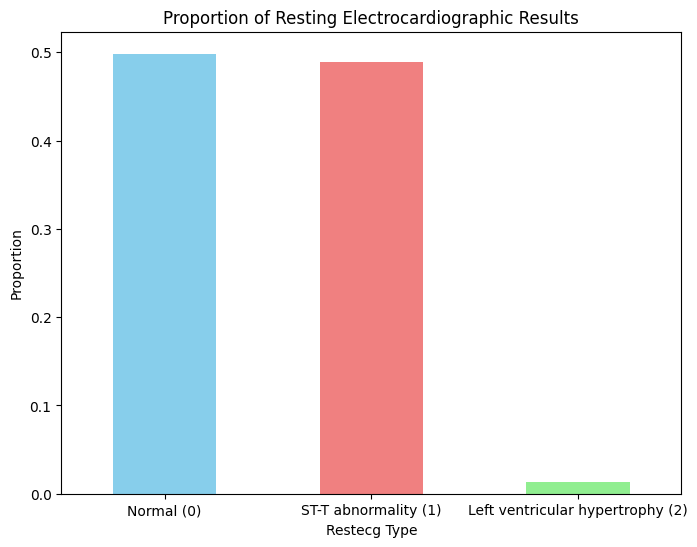

In [26]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 6))
df['restecg'].value_counts(normalize=True).plot(
    kind='bar',
    title='Proportion of Resting Electrocardiographic Results',
    ylabel='Proportion',
    xlabel='Restecg Type',
    rot=0,
    color=['skyblue', 'lightcoral', 'lightgreen']
)
plt.xticks(ticks=[0, 1, 2], labels=['Normal (0)', 'ST-T abnormality (1)', 'Left ventricular hypertrophy (2)'])
plt.show()

### exang = Exercise-Induced Angina



*   0 = No chest pain during exercise
*   1 = Chest pain during exercise


In [27]:
round(df.exang.value_counts(normalize=True), 3)

,proportion
exang,
0,0.673
1,0.327


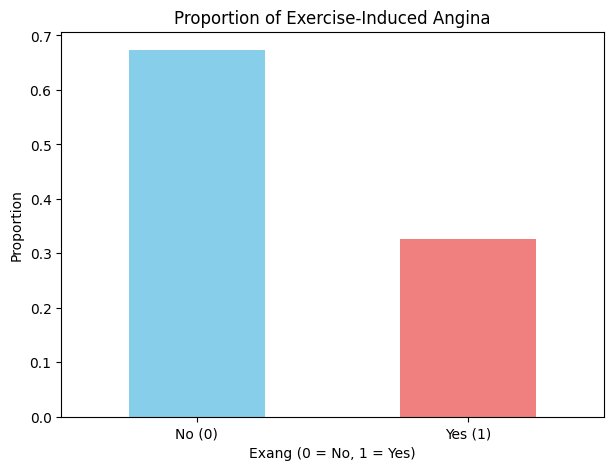

In [28]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 5))
df['exang'].value_counts(normalize=True).plot(
    kind='bar',
    title='Proportion of Exercise-Induced Angina',
    ylabel='Proportion',
    xlabel='Exang (0 = No, 1 = Yes)',
    rot=0, # Keep x-axis labels horizontal
    color=['skyblue', 'lightcoral']
)
plt.xticks(ticks=[0, 1], labels=['No (0)', 'Yes (1)'])
plt.show()

### slope = Slope of Peak Exercise ST Segment



*   0 = Upsloping (generally normal)
*   1 = Flat (possible abnormality)
*   2 = Downsloping (strong sign of heart disease)

In [29]:
round(df.slope.value_counts(normalize=True), 3)

,proportion
slope,
0,0.469
1,0.462
2,0.069


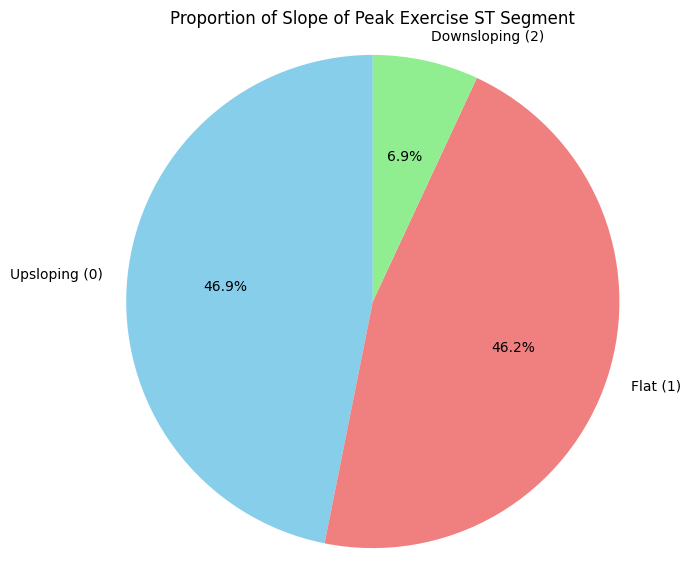

In [30]:
import matplotlib.pyplot as plt

# Calculate the value counts for the 'slope' column
slope_counts = df['slope'].value_counts(normalize=True)

# Define labels and colors for the pie chart
labels = ['Upsloping (0)', 'Flat (1)', 'Downsloping (2)']
colors = ['skyblue', 'lightcoral', 'lightgreen']

# Create the pie chart
plt.figure(figsize=(7, 7))
plt.pie(slope_counts, labels=labels, colors=colors, autopct='%1.1f%%', startangle=90)
plt.title('Proportion of Slope of Peak Exercise ST Segment')
plt.axis('equal') # Equal aspect ratio ensures that pie is drawn as a circle.
plt.show()

### ca = Number of Major Vessels



*   0 = No major vessels detected
*   1 = 1 major vessel detected
*   2 = 2 major vessels detected
*   3 = 3 major vessels detected
*   4 = 4 major vessels detected (rare)

In [31]:
round(df.ca.value_counts(normalize=True), 3)

,proportion
ca,
0,0.594
1,0.215
2,0.125
3,0.066


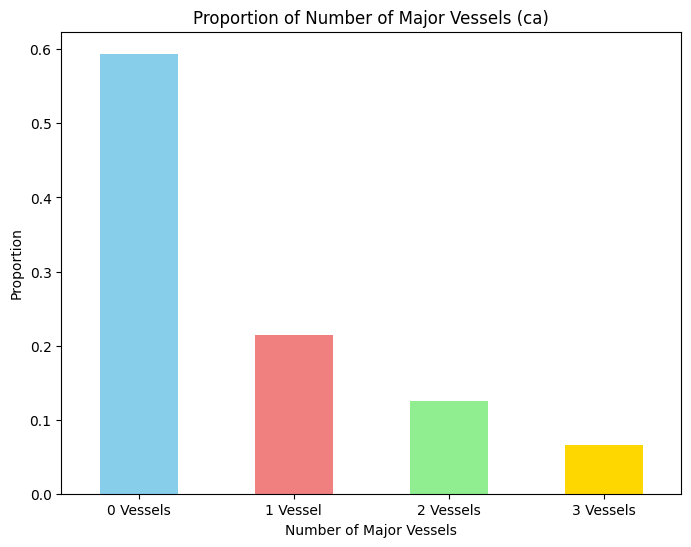

In [32]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 6))
df['ca'].value_counts(normalize=True).plot(
    kind='bar',
    title='Proportion of Number of Major Vessels (ca)',
    ylabel='Proportion',
    xlabel='Number of Major Vessels',
    rot=0,
    color=['skyblue', 'lightcoral', 'lightgreen', 'gold']
)
plt.xticks(ticks=[0, 1, 2, 3], labels=['0 Vessels', '1 Vessel', '2 Vessels', '3 Vessels'])
plt.show()

### thal = Thalassemia



*   1 = Normal
*   2 = Fixed defect (permanent issue)
*   3 = Reversible defect (temporary issue under stress)

In [33]:
round(df.thal.value_counts(normalize=True), 3)

,proportion
thal,
1,0.554
3,0.386
2,0.059


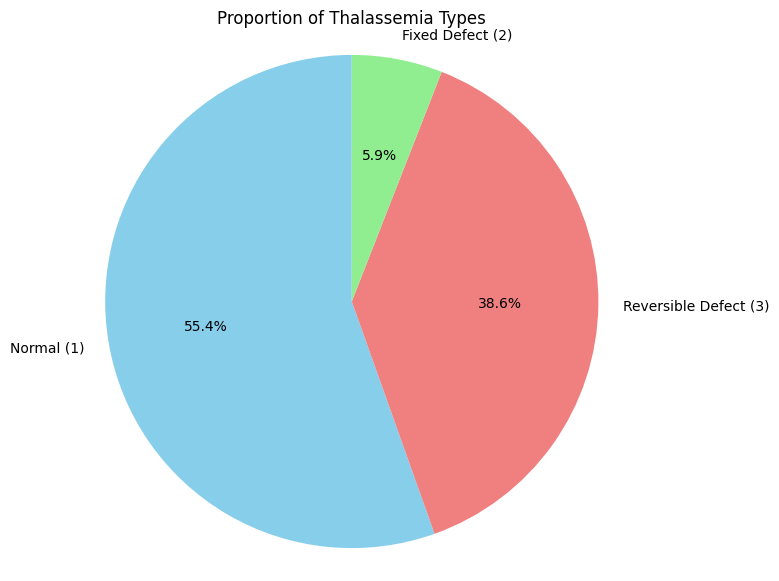

In [34]:
import matplotlib.pyplot as plt

# Calculate the value counts for the 'thal' column
thal_counts = df['thal'].value_counts(normalize=True)

# Define labels and colors for the pie chart
labels = ['Normal (1)', 'Reversible Defect (3)', 'Fixed Defect (2)']
colors = ['skyblue', 'lightcoral', 'lightgreen']

# Create the pie chart
plt.figure(figsize=(7, 7))
plt.pie(thal_counts, labels=labels, colors=colors, autopct='%1.1f%%', startangle=90)
plt.title('Proportion of Thalassemia Types')
plt.axis('equal') # Equal aspect ratio ensures that pie is drawn as a circle.
plt.show()

# Independent variable (Quantitative)

## age

In [35]:
df['ï»¿age'].describe()

,ï»¿age
count,303.000000
mean,54.438944
std,9.038662
min,29.000000
25%,48.000000
50%,56.000000
75%,61.000000
max,77.000000


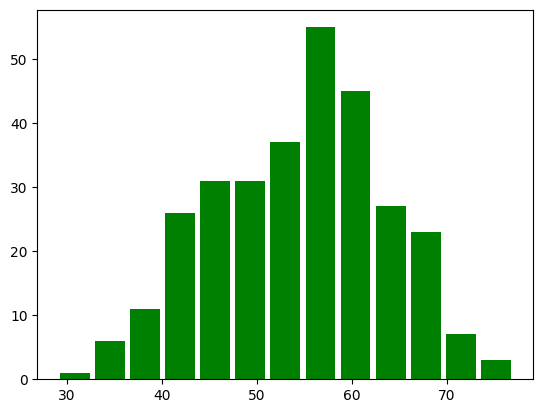

In [36]:
import matplotlib.pyplot as plt

plt.hist(x=df['ï»¿age'], bins='auto', rwidth=0.85, color="green")
plt.show()

## chol (cholesterol)

In [37]:
df['chol'].describe()

,chol
count,303.000000
mean,246.693069
std,51.776918
min,126.000000
25%,211.000000
50%,241.000000
75%,275.000000
max,564.000000


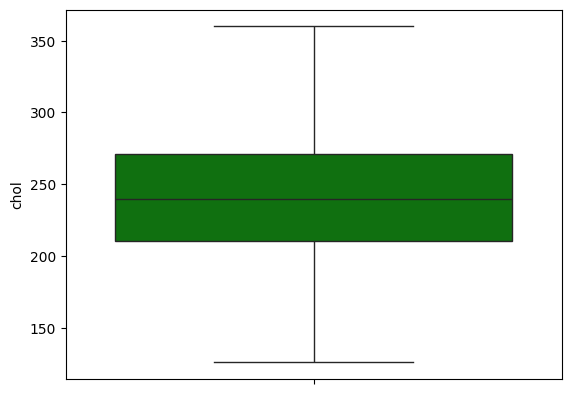

In [38]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.boxplot(y=df_cleaned.chol, color="green")
plt.show()

## trestbps (blood pressure)

In [39]:
df['trestbps'].describe()

,trestbps
count,303.000000
mean,131.689769
std,17.599748
min,94.000000
25%,120.000000
50%,130.000000
75%,140.000000
max,200.000000


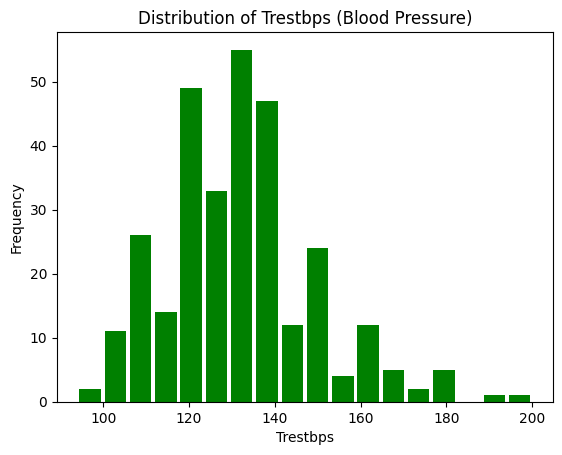

In [40]:
import matplotlib.pyplot as plt

plt.hist(x=df['trestbps'], bins='auto', rwidth=0.85, color="green")
plt.title('Distribution of Trestbps (Blood Pressure)')
plt.xlabel('Trestbps')
plt.ylabel('Frequency')
plt.show()

## thalach (heart rate)

In [41]:
df['thalach'].describe()

,thalach
count,303.000000
mean,149.607261
std,22.875003
min,71.000000
25%,133.500000
50%,153.000000
75%,166.000000
max,202.000000


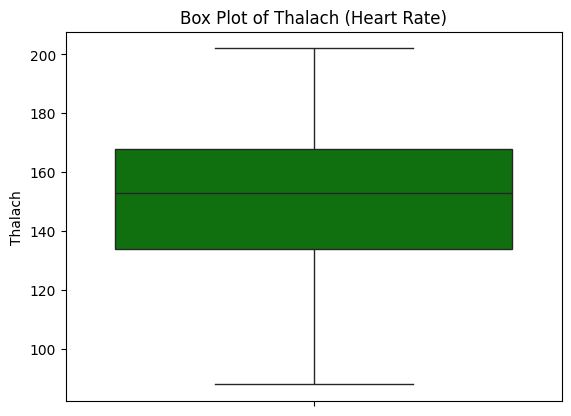

In [42]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.boxplot(y=df_cleaned.thalach, color="green")
plt.title('Box Plot of Thalach (Heart Rate)')
plt.ylabel('Thalach')
plt.show()

## oldpeak

In [43]:
df['oldpeak'].describe()

,oldpeak
count,303.000000
mean,1.039604
std,1.161075
min,0.000000
25%,0.000000
50%,0.800000
75%,1.600000
max,6.200000


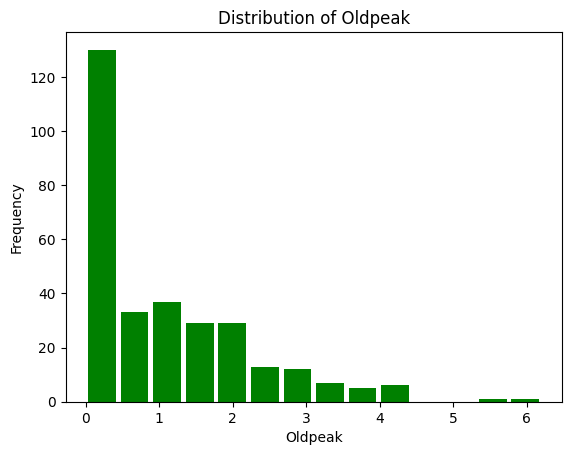

In [44]:
import matplotlib.pyplot as plt

plt.hist(x=df['oldpeak'], bins='auto', rwidth=0.85, color="green")
plt.title('Distribution of Oldpeak')
plt.xlabel('Oldpeak')
plt.ylabel('Frequency')
plt.show()

# Bivariate Analysis

## Bivariate Analysis between Dependent variable and Independent (Qualitative) variables

### Heart disease vs Gender

In [45]:
round(pd.crosstab(df_cleaned['sex'], df_cleaned['target'])/len(df_cleaned), 2)

target,0,1
sex,,
0,0.24,0.06
1,0.32,0.38


<Axes: xlabel='target', ylabel='Count'>

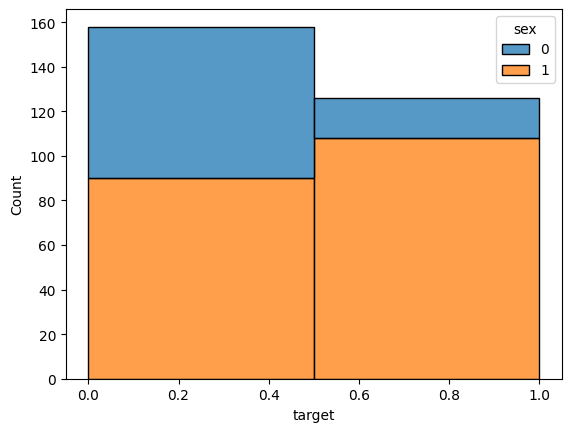

In [46]:
sns.histplot(binwidth=0.5, x="target", hue="sex", data=df_cleaned, stat="count", multiple="stack")

### Heart disease vs Chest pain

In [47]:
round(pd.crosstab(df_cleaned['cp'], df_cleaned['target'])/len(df_cleaned), 2)

target,0,1
cp,,
0,0.05,0.02
1,0.14,0.03
2,0.23,0.06
3,0.13,0.33


<Axes: xlabel='target', ylabel='Count'>

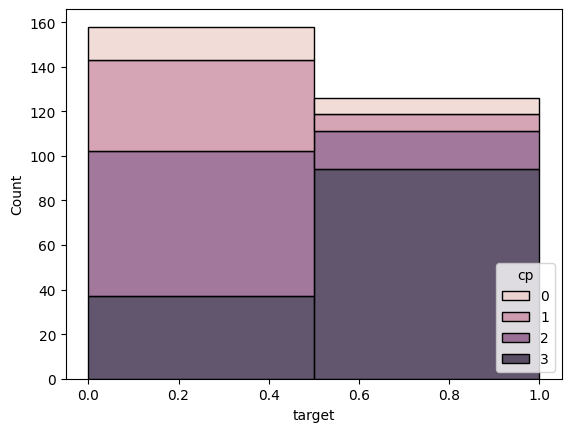

In [48]:
sns.histplot(binwidth=0.5, x="target", hue="cp", data=df_cleaned, stat="count", multiple="stack")

### Heart disease vs blood sugar

In [49]:
round(pd.crosstab(df_cleaned['fbs'], df_cleaned['target'])/len(df_cleaned), 2)

target,0,1
fbs,,
0,0.48,0.38
1,0.07,0.07


<Axes: xlabel='target', ylabel='Count'>

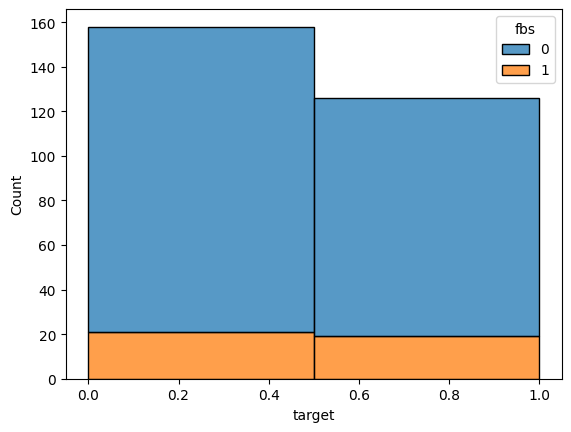

In [50]:
sns.histplot(binwidth=0.5, x="target", hue="fbs", data=df_cleaned, stat="count", multiple="stack")

### Heart disease vs exercise

In [51]:
round(pd.crosstab(df_cleaned['exang'], df_cleaned['target'])/len(df_cleaned), 2)

target,0,1
exang,,
0,0.48,0.20
1,0.08,0.24


<Axes: xlabel='target', ylabel='Count'>

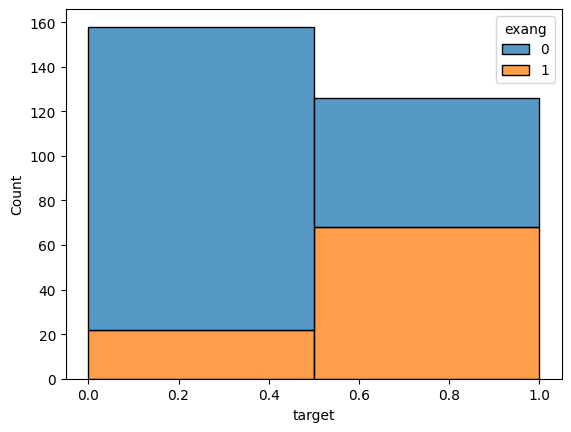

In [52]:
sns.histplot(binwidth=0.5, x="target", hue="exang", data=df_cleaned, stat="count", multiple="stack")

### Heart disease vs electrocardiographic

In [53]:
round(pd.crosstab(df_cleaned['restecg'], df_cleaned['target'])/len(df_cleaned), 2)

target,0,1
restecg,,
0,0.33,0.18
1,0.00,0.00
2,0.23,0.26


<Axes: xlabel='target', ylabel='Count'>

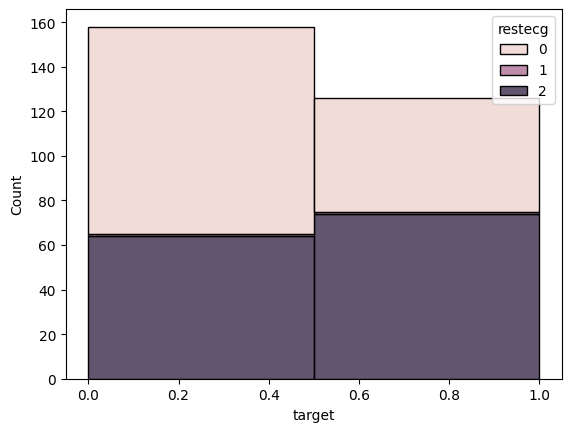

In [54]:
sns.histplot(binwidth=0.5, x="target", hue="restecg", data=df_cleaned, stat="count", multiple="stack")

### Histograms and Pair Plot for Selected Numerical Features


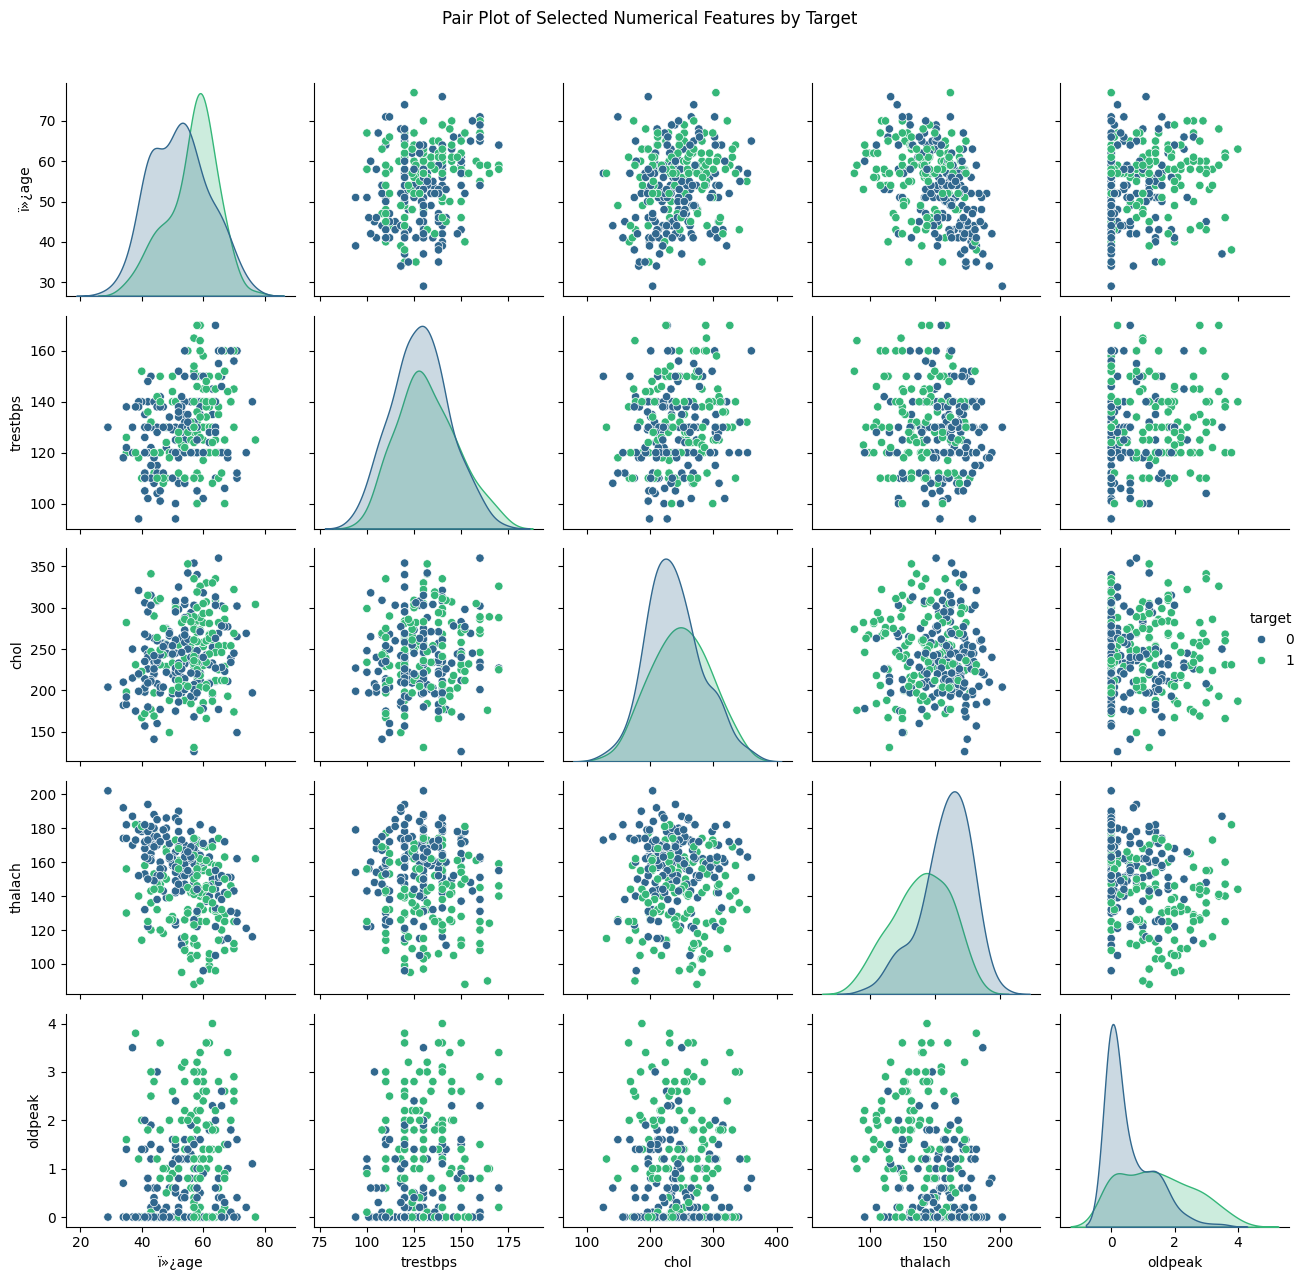

In [55]:
import matplotlib.pyplot as plt
import seaborn as sns

# Define the numerical columns for which to generate plots
selected_numerical_cols = ['ï»¿age', 'trestbps', 'chol', 'thalach', 'oldpeak']

# Generate a pair plot for the selected numerical columns from df_cleaned
# We'll include the 'target' variable to see how it relates to these numerical features
sns.pairplot(df_cleaned, vars=selected_numerical_cols, hue='target', palette='viridis', diag_kind='kde')
plt.suptitle('Pair Plot of Selected Numerical Features by Target', y=1.02) # Add a title for the whole figure
plt.tight_layout()
plt.show()

### Histograms for numerical features

###Age

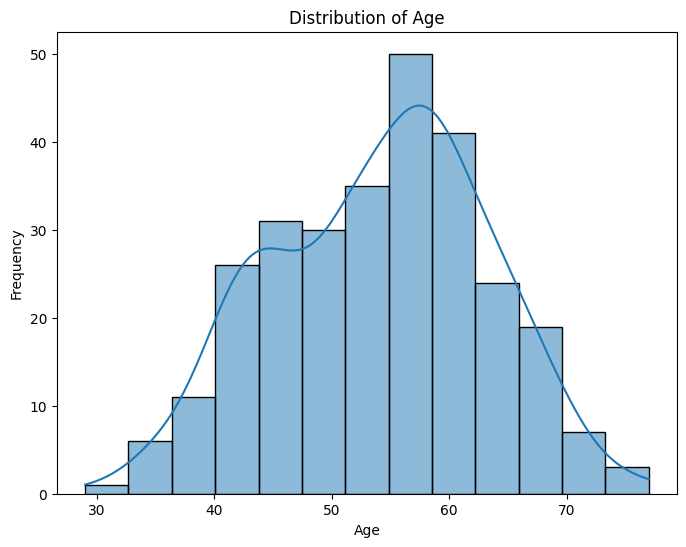

In [56]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 6))
sns.histplot(df_cleaned['ï»¿age'], kde=True)
plt.title('Distribution of Age')
plt.xlabel('Age')
plt.ylabel('Frequency')
plt.show()

### Cholesterol

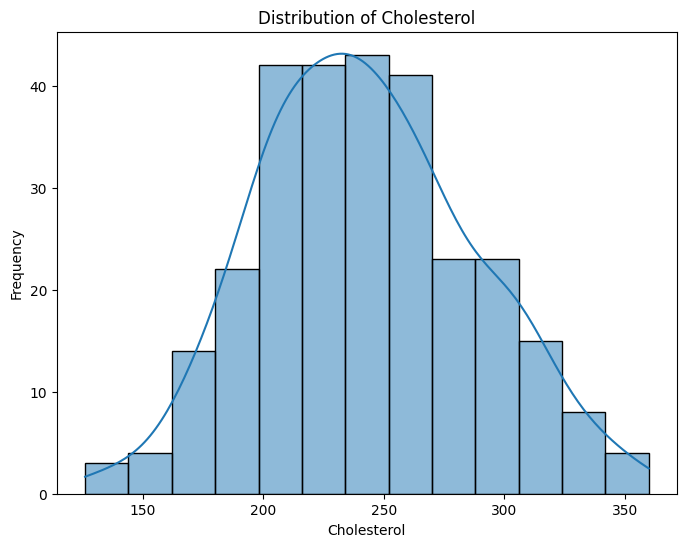

In [57]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 6))
sns.histplot(df_cleaned['chol'], kde=True)
plt.title('Distribution of Cholesterol')
plt.xlabel('Cholesterol')
plt.ylabel('Frequency')
plt.show()

### Blood pressure

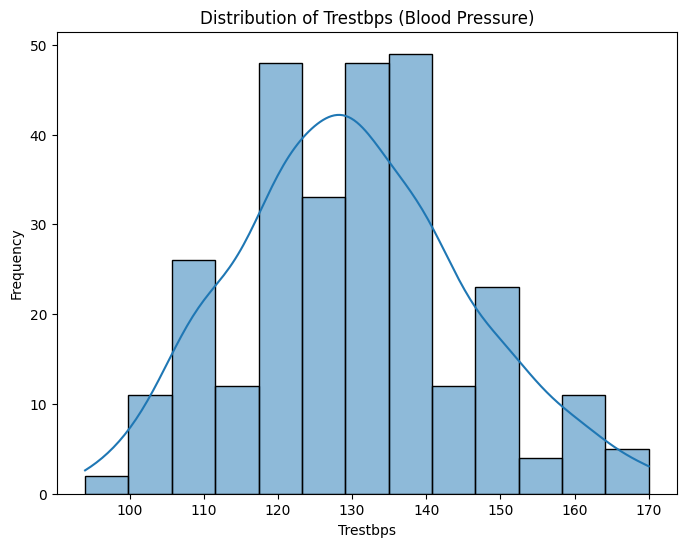

In [58]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 6))
sns.histplot(df_cleaned['trestbps'], kde=True)
plt.title('Distribution of Trestbps (Blood Pressure)')
plt.xlabel('Trestbps')
plt.ylabel('Frequency')
plt.show()

### Heart rate

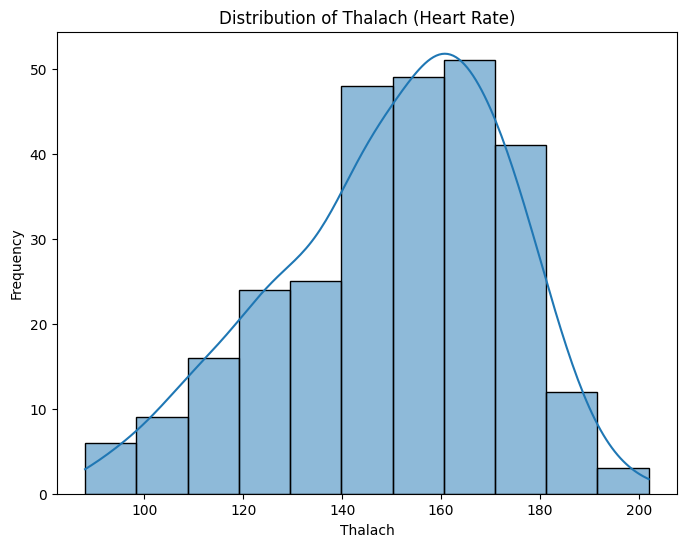

In [59]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 6))
sns.histplot(df_cleaned['thalach'], kde=True)
plt.title('Distribution of Thalach (Heart Rate)')
plt.xlabel('Thalach')
plt.ylabel('Frequency')
plt.show()

### oldpeak


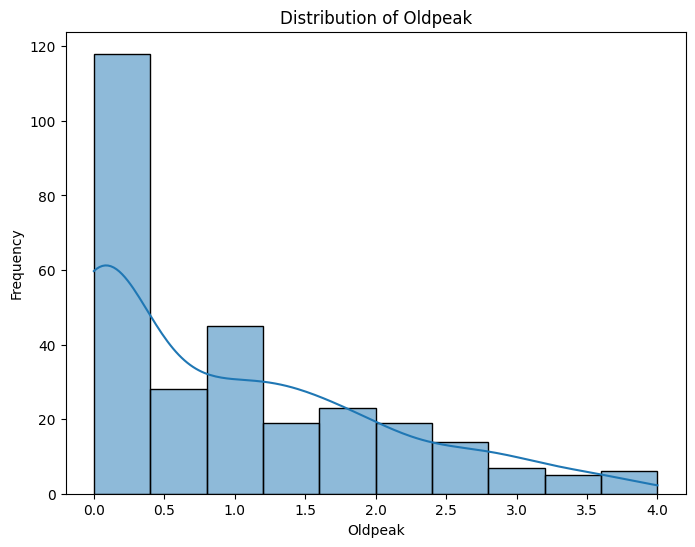

In [60]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 6))
sns.histplot(df_cleaned['oldpeak'], kde=True)
plt.title('Distribution of Oldpeak')
plt.xlabel('Oldpeak')
plt.ylabel('Frequency')
plt.show()

### Bivariate Analysis: Categorical Features vs. Target


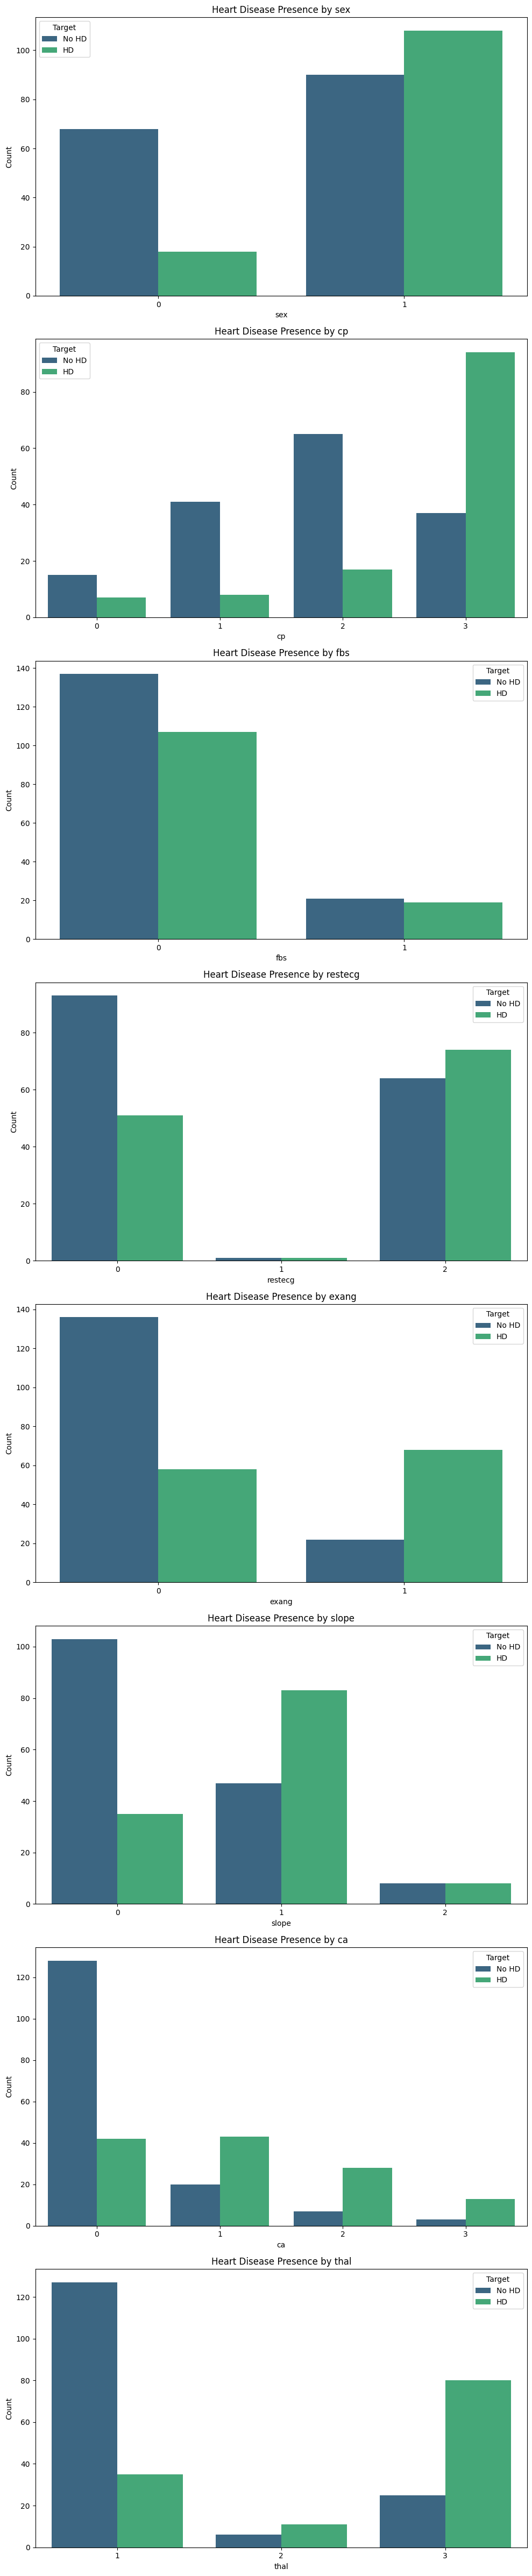

In [61]:
import matplotlib.pyplot as plt
import seaborn as sns

# Assuming 'categorical_cols' is defined from previous steps
categorical_cols = ['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'ca', 'thal']

# Create subplots for each categorical column against the 'target'
fig, axes = plt.subplots(nrows=len(categorical_cols), ncols=1, figsize=(10, 6 * len(categorical_cols)))

for i, col in enumerate(categorical_cols):
    sns.countplot(data=df_cleaned, x=col, hue='target', palette='viridis', ax=axes[i])
    axes[i].set_title(f'Heart Disease Presence by {col}')
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Count')
    axes[i].legend(title='Target', labels=['No HD', 'HD'])

plt.tight_layout()
plt.show()

### Correlation Heatmap

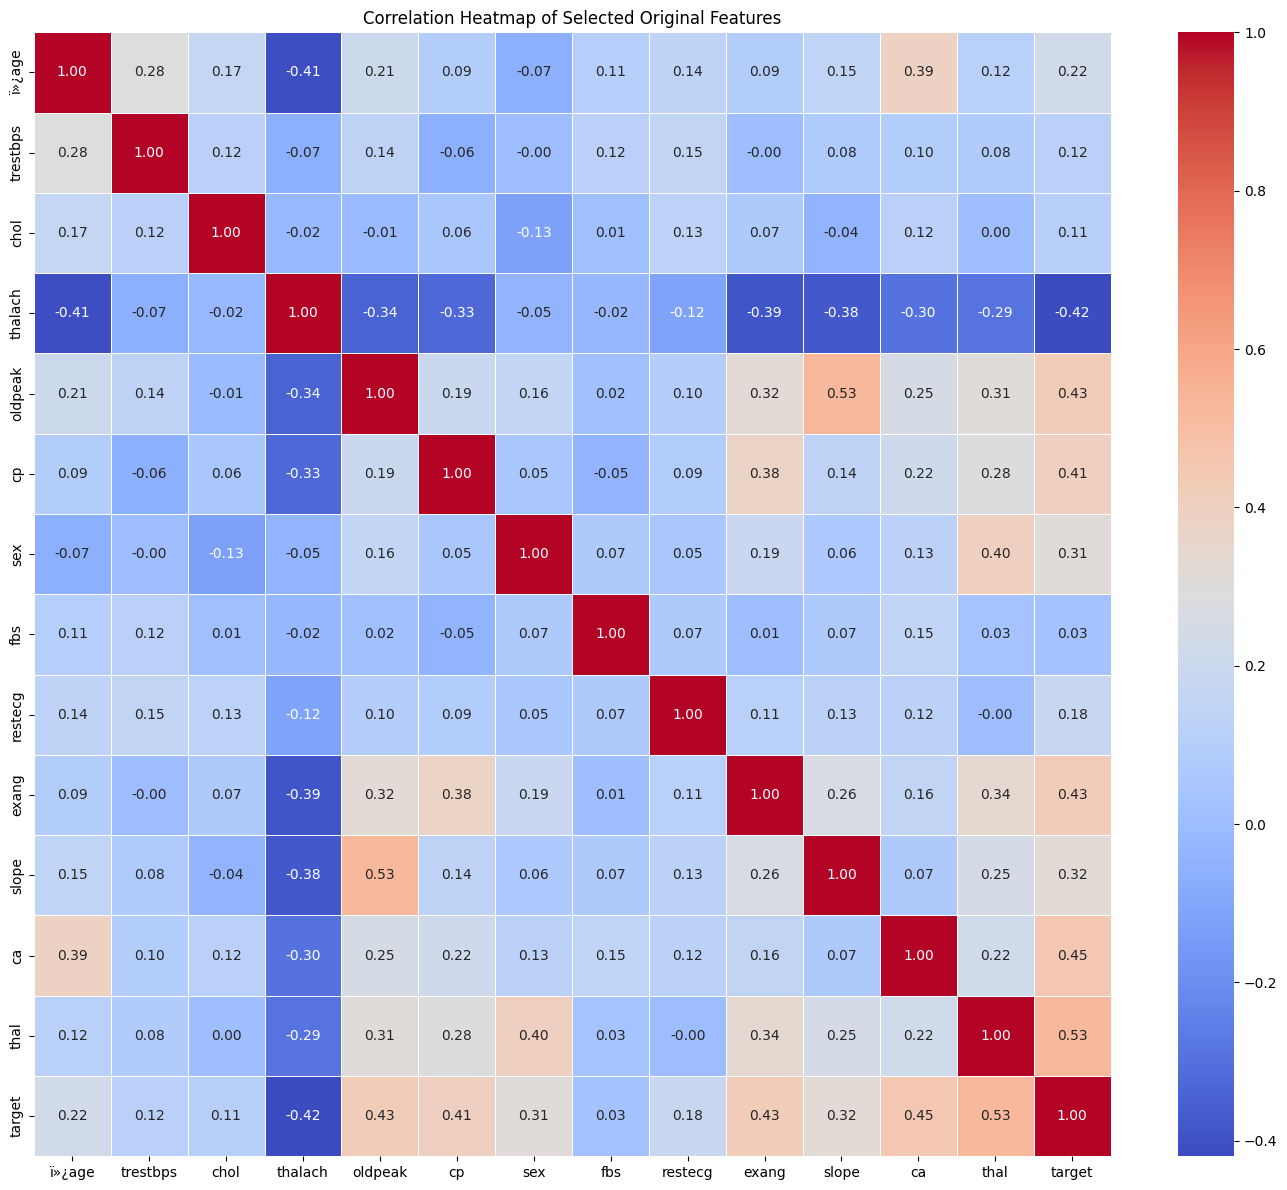

In [62]:
import matplotlib.pyplot as plt
import seaborn as sns

# Select relevant columns from df_cleaned for a more focused heatmap
# This includes numerical features and original integer-encoded categorical features
selected_cols_for_corr = [
    'ï»¿age', 'trestbps', 'chol', 'thalach', 'oldpeak', # Original numerical features
    'cp', 'sex', 'fbs', 'restecg', 'exang', 'slope', 'ca', 'thal', # Original integer-encoded categorical features
    'target' # Target variable
]

# Calculate the correlation matrix for these selected columns from df_cleaned
correlation_matrix_selected = df_cleaned[selected_cols_for_corr].corr()

plt.figure(figsize=(14, 12)) # Adjust figure size for better readability
sns.heatmap(correlation_matrix_selected, annot=True, cmap='coolwarm', fmt=".2f", linewidths=.5)
plt.title('Correlation Heatmap of Selected Original Features')
plt.tight_layout()
plt.show()

# Part 3

## Prepare Data for Model Training

In [63]:
from sklearn.model_selection import train_test_split

# Define features (X) and target (y)
X = df_encoded.drop('target', axis=1)
y = df_encoded['target']

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print(f"X_train shape: {X_train.shape}")
print(f"X_test shape: {X_test.shape}")
print(f"y_train shape: {y_train.shape}")
print(f"y_test shape: {y_test.shape}")

X_train shape: (227, 28)
X_test shape: (57, 28)
y_train shape: (227,)
y_test shape: (57,)


##Import Model Training Libraries

In [64]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import GridSearchCV, RandomizedSearchCV
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, ConfusionMatrixDisplay,
    make_scorer
)

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
import xgboost as xgb

baseline_metrics = {}
tuned_metrics = {}
baseline_predictions = {}
tuned_predictions = {}
best_models = {}
fit_check_results = {}
best_hyperparameters = {}
cv_scores = {}

# All five metrics are considered during model evaluation
scoring_metrics = {
    'Accuracy': 'accuracy',
    'Precision': make_scorer(precision_score, zero_division=0),
    'Recall': make_scorer(recall_score, zero_division=0),
    'F1-Score': make_scorer(f1_score, zero_division=0),
    'ROC-AUC': 'roc_auc'
}

##Helper Functions

In [65]:
def evaluate_model(model_name, model, X_test, y_test, storage_dict, prediction_dict):
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]

    metrics = {
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred, zero_division=0),
        'Recall': recall_score(y_test, y_pred, zero_division=0),
        'F1-Score': f1_score(y_test, y_pred, zero_division=0),
        'ROC-AUC': roc_auc_score(y_test, y_proba)
    }

    storage_dict[model_name] = metrics
    prediction_dict[model_name] = y_pred

    print(f"{model_name} Evaluation Metrics")
    for metric_name, metric_value in metrics.items():
        print(f"{metric_name}: {metric_value:.4f}")


def check_model_fit(model_name, model, X_train, y_train, X_test, y_test):
    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)

    train_acc = accuracy_score(y_train, train_pred)
    test_acc = accuracy_score(y_test, test_pred)
    train_f1 = f1_score(y_train, train_pred, zero_division=0)
    test_f1 = f1_score(y_test, test_pred, zero_division=0)

    gap = train_acc - test_acc

    if gap > 0.10:
        status = "Possible Overfitting"
    elif train_acc < 0.75 and test_acc < 0.75:
        status = "Possible Underfitting"
    else:
        status = "Reasonable Fit"

    fit_check_results[model_name] = {
        'Train Accuracy': train_acc,
        'Test Accuracy': test_acc,
        'Train F1-Score': train_f1,
        'Test F1-Score': test_f1,
        'Accuracy Gap': gap,
        'Fit Status': status
    }


def plot_confusion_matrix(model_name, y_test, y_pred, model_type):
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        y_pred,
        display_labels=['No Heart Disease', 'Heart Disease'],
        cmap='Blues'
    )

    plt.title(f'Confusion Matrix - {model_type} {model_name}')
    plt.show()

##Model 01 - Logistic Regression

In [66]:
log_reg_baseline = LogisticRegression(random_state=42, solver='liblinear')
log_reg_baseline.fit(X_train, y_train)

evaluate_model(
    'Logistic Regression',
    log_reg_baseline,
    X_test,
    y_test,
    baseline_metrics,
    baseline_predictions
)

Logistic Regression Evaluation Metrics
Accuracy: 0.8772
Precision: 0.8750
Recall: 0.8400
F1-Score: 0.8571
ROC-AUC: 0.9338


##Model 02 - Random Forest Classifier

In [67]:
rf_baseline = RandomForestClassifier(random_state=42)
rf_baseline.fit(X_train, y_train)

evaluate_model(
    'Random Forest',
    rf_baseline,
    X_test,
    y_test,
    baseline_metrics,
    baseline_predictions
)

Random Forest Evaluation Metrics
Accuracy: 0.8070
Precision: 0.7692
Recall: 0.8000
F1-Score: 0.7843
ROC-AUC: 0.8919


## Model 03: Support Vector Machine


In [68]:
svm_baseline = SVC(random_state=42, probability=True)
svm_baseline.fit(X_train, y_train)

evaluate_model(
    'Support Vector Machine',
    svm_baseline,
    X_test,
    y_test,
    baseline_metrics,
    baseline_predictions
)

Support Vector Machine Evaluation Metrics
Accuracy: 0.8596
Precision: 0.8400
Recall: 0.8400
F1-Score: 0.8400
ROC-AUC: 0.9038


## Model 04: Decision Tree

In [69]:
dt_baseline = DecisionTreeClassifier(random_state=42)
dt_baseline.fit(X_train, y_train)

evaluate_model(
    'Decision Tree',
    dt_baseline,
    X_test,
    y_test,
    baseline_metrics,
    baseline_predictions
)

Decision Tree Evaluation Metrics
Accuracy: 0.7018
Precision: 0.6667
Recall: 0.6400
F1-Score: 0.6531
ROC-AUC: 0.6950


## Model 05: AdaBoost Classifier

In [70]:
ada_baseline = AdaBoostClassifier(
    estimator=DecisionTreeClassifier(max_depth=1, random_state=42),
    n_estimators=50,
    random_state=42
)

ada_baseline.fit(X_train, y_train)

evaluate_model(
    'AdaBoost',
    ada_baseline,
    X_test,
    y_test,
    baseline_metrics,
    baseline_predictions
)

AdaBoost Evaluation Metrics
Accuracy: 0.8421
Precision: 0.8333
Recall: 0.8000
F1-Score: 0.8163
ROC-AUC: 0.9300


## Model 06: XGBoost Classifier

In [71]:
xgb_baseline = xgb.XGBClassifier(
    objective='binary:logistic',
    eval_metric='logloss',
    random_state=42
)

xgb_baseline.fit(X_train, y_train)

evaluate_model(
    'XGBoost',
    xgb_baseline,
    X_test,
    y_test,
    baseline_metrics,
    baseline_predictions
)

XGBoost Evaluation Metrics
Accuracy: 0.8246
Precision: 0.8000
Recall: 0.8000
F1-Score: 0.8000
ROC-AUC: 0.9038


## Model Evaluation Summary

In [72]:
baseline_df = pd.DataFrame.from_dict(baseline_metrics, orient='index')
baseline_df = baseline_df.round(4)

display(baseline_df.sort_values(by='Accuracy', ascending=False))

,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Logistic Regression,0.8772,0.8750,0.84,0.8571,0.9338
Support Vector Machine,0.8596,0.8400,0.84,0.8400,0.9038
AdaBoost,0.8421,0.8333,0.80,0.8163,0.9300
XGBoost,0.8246,0.8000,0.80,0.8000,0.9038
Random Forest,0.8070,0.7692,0.80,0.7843,0.8919
Decision Tree,0.7018,0.6667,0.64,0.6531,0.6950


#Confusion Matrices and ROC Curves for Baseline ML Models

##Model 01 -Logistic Regression

###Confusion Matrix

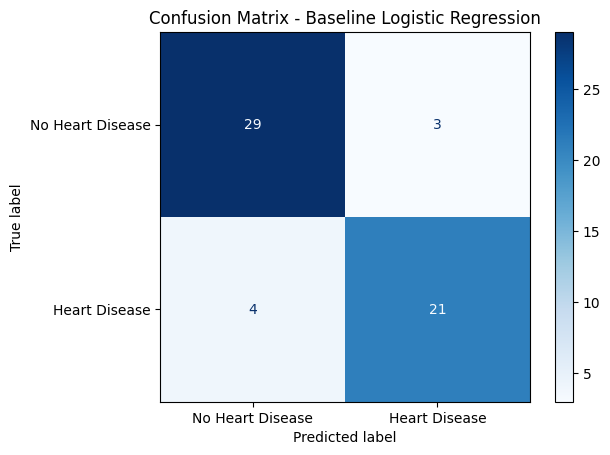

In [73]:
plot_confusion_matrix(
    'Logistic Regression',
    y_test,
    baseline_predictions['Logistic Regression'],
    'Baseline'
)

###ROC Curve

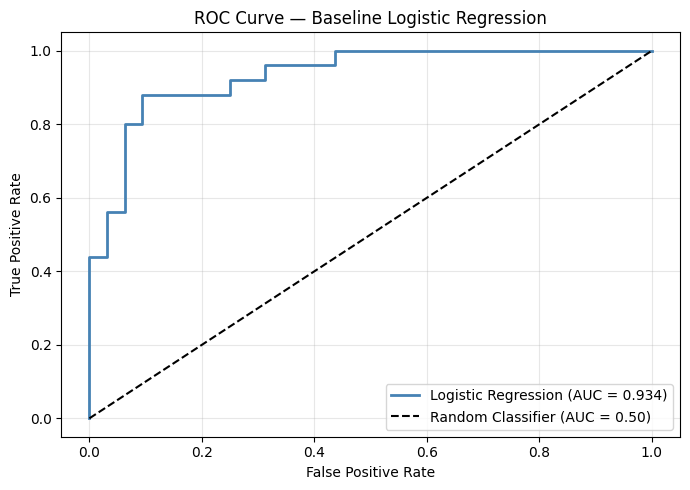

In [74]:
from sklearn.metrics import roc_curve, auc

y_proba_lr = log_reg_baseline.predict_proba(X_test)[:, 1]
fpr_lr, tpr_lr, _ = roc_curve(y_test, y_proba_lr)
roc_auc_lr = auc(fpr_lr, tpr_lr)

plt.figure(figsize=(7, 5))
plt.plot(fpr_lr, tpr_lr, color='steelblue', lw=2, label=f'Logistic Regression (AUC = {roc_auc_lr:.3f})')
plt.plot([0, 1], [0, 1], 'k--', lw=1.5, label='Random Classifier (AUC = 0.50)')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Baseline Logistic Regression')
plt.legend(loc='lower right')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

##Model 02 - Random Forest Classifier

###Confusion Matrix

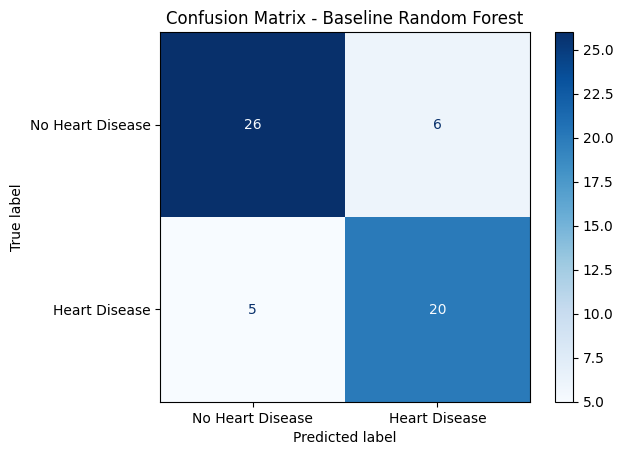

In [75]:
plot_confusion_matrix(
    'Random Forest',
    y_test,
    baseline_predictions['Random Forest'],
    'Baseline'
)

##ROC Curve

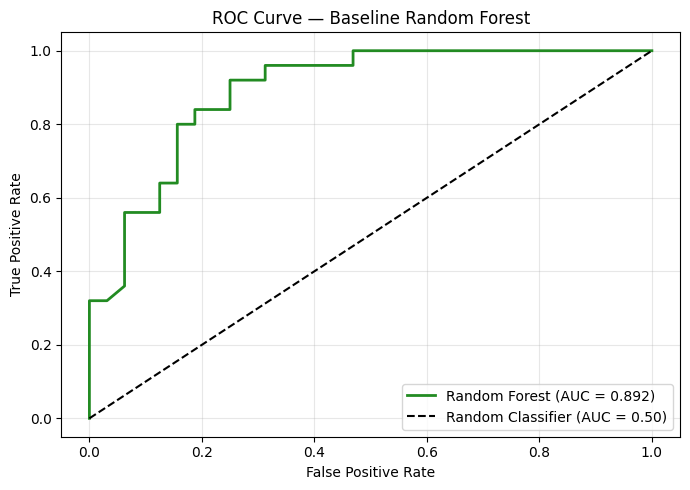

In [76]:
y_proba_rf = rf_baseline.predict_proba(X_test)[:, 1]
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_proba_rf)
roc_auc_rf = auc(fpr_rf, tpr_rf)

plt.figure(figsize=(7, 5))
plt.plot(fpr_rf, tpr_rf, color='forestgreen', lw=2, label=f'Random Forest (AUC = {roc_auc_rf:.3f})')
plt.plot([0, 1], [0, 1], 'k--', lw=1.5, label='Random Classifier (AUC = 0.50)')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve  Baseline Random Forest')
plt.legend(loc='lower right')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

##Model 03 - Support Vector Machine

###Confusion Matrix

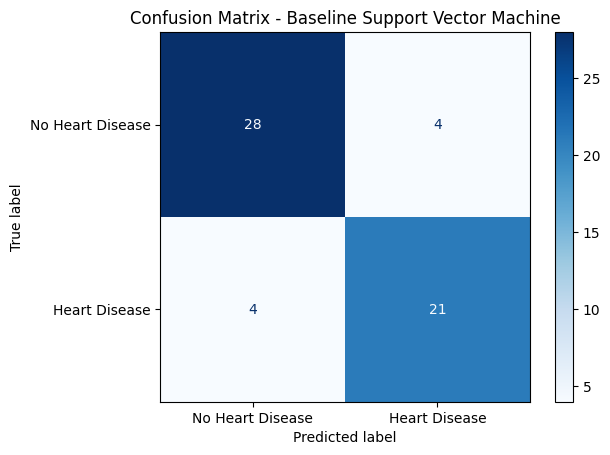

In [77]:
plot_confusion_matrix(
    'Support Vector Machine',
    y_test,
    baseline_predictions['Support Vector Machine'],
    'Baseline'
)

###ROC Curve

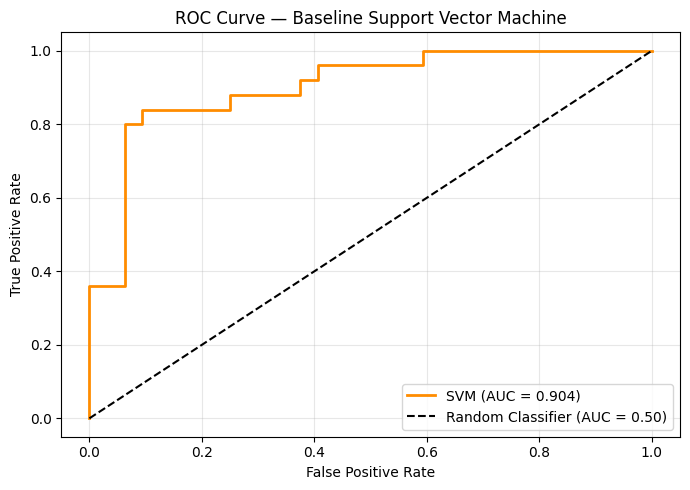

In [78]:
y_proba_svm = svm_baseline.predict_proba(X_test)[:, 1]
fpr_svm, tpr_svm, _ = roc_curve(y_test, y_proba_svm)
roc_auc_svm = auc(fpr_svm, tpr_svm)

plt.figure(figsize=(7, 5))
plt.plot(fpr_svm, tpr_svm, color='darkorange', lw=2, label=f'SVM (AUC = {roc_auc_svm:.3f})')
plt.plot([0, 1], [0, 1], 'k--', lw=1.5, label='Random Classifier (AUC = 0.50)')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Baseline Support Vector Machine')
plt.legend(loc='lower right')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

##Model 04 - Decision Tree

###Confusion Matrix

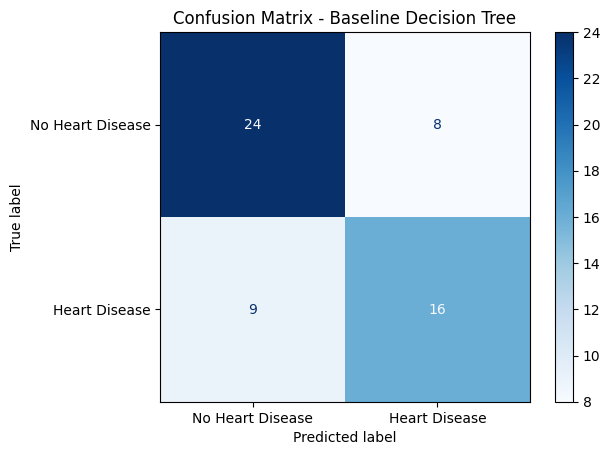

In [79]:
plot_confusion_matrix(
    'Decision Tree',
    y_test,
    baseline_predictions['Decision Tree'],
    'Baseline'
)

###ROC Curve

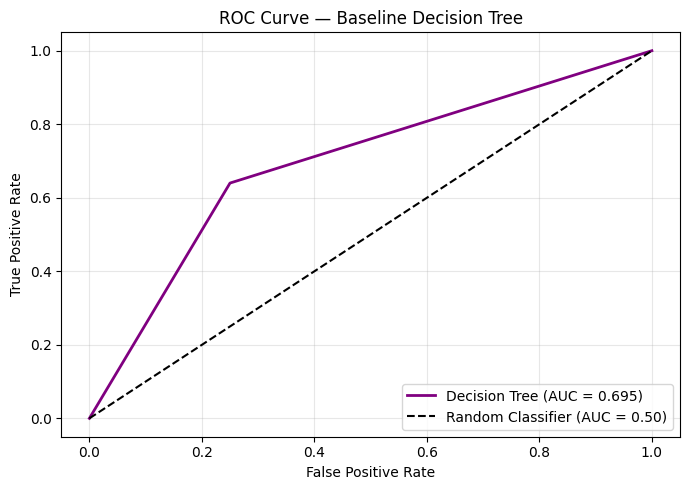

In [80]:
y_proba_dt = dt_baseline.predict_proba(X_test)[:, 1]
fpr_dt, tpr_dt, _ = roc_curve(y_test, y_proba_dt)
roc_auc_dt = auc(fpr_dt, tpr_dt)

plt.figure(figsize=(7, 5))
plt.plot(fpr_dt, tpr_dt, color='purple', lw=2, label=f'Decision Tree (AUC = {roc_auc_dt:.3f})')
plt.plot([0, 1], [0, 1], 'k--', lw=1.5, label='Random Classifier (AUC = 0.50)')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Baseline Decision Tree')
plt.legend(loc='lower right')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

##Model 05 - AdaBoost Classifier

###Confusion Matrix

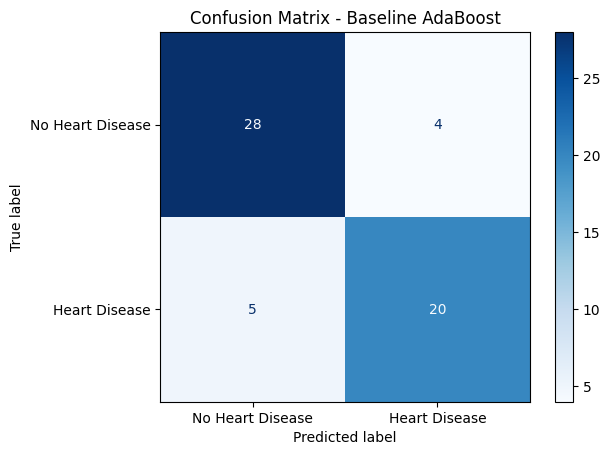

In [81]:
plot_confusion_matrix(
    'AdaBoost',
    y_test,
    baseline_predictions['AdaBoost'],
    'Baseline'
)

###ROC Curve

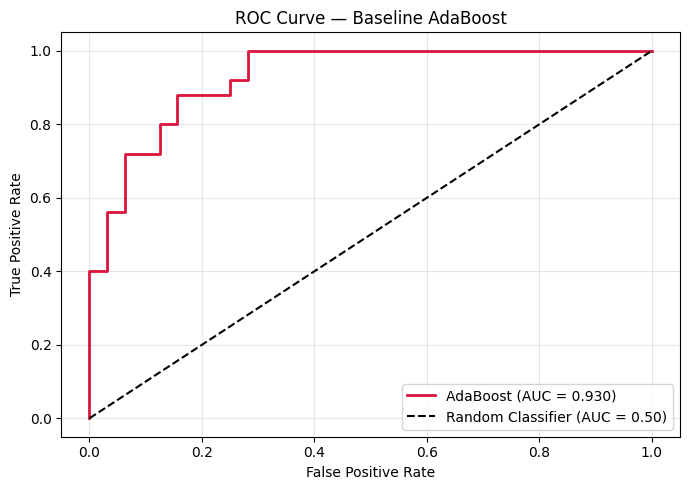

In [82]:
y_proba_ada = ada_baseline.predict_proba(X_test)[:, 1]
fpr_ada, tpr_ada, _ = roc_curve(y_test, y_proba_ada)
roc_auc_ada = auc(fpr_ada, tpr_ada)

plt.figure(figsize=(7, 5))
plt.plot(fpr_ada, tpr_ada, color='crimson', lw=2, label=f'AdaBoost (AUC = {roc_auc_ada:.3f})')
plt.plot([0, 1], [0, 1], 'k--', lw=1.5, label='Random Classifier (AUC = 0.50)')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Baseline AdaBoost')
plt.legend(loc='lower right')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

##Model 06 - XGBoost Classifier

###Confusion Matrix

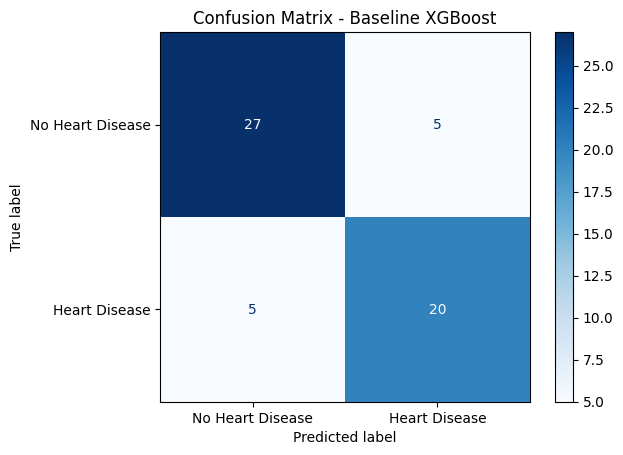

In [83]:
plot_confusion_matrix(
    'XGBoost',
    y_test,
    baseline_predictions['XGBoost'],
    'Baseline'
)

###ROC Curve

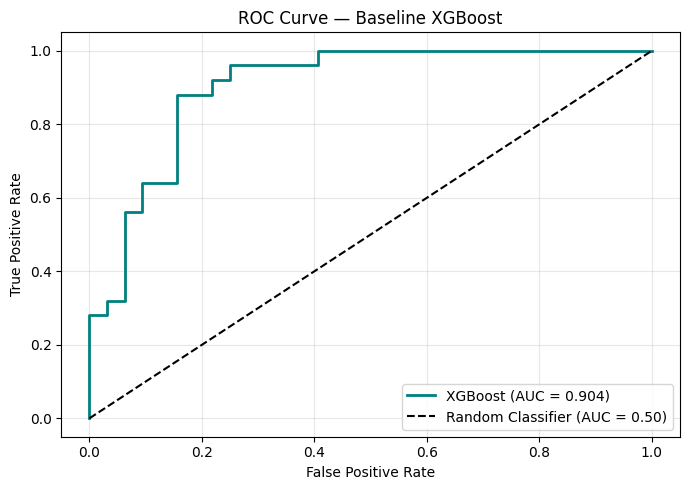

In [84]:
y_proba_xgb = xgb_baseline.predict_proba(X_test)[:, 1]
fpr_xgb, tpr_xgb, _ = roc_curve(y_test, y_proba_xgb)
roc_auc_xgb = auc(fpr_xgb, tpr_xgb)

plt.figure(figsize=(7, 5))
plt.plot(fpr_xgb, tpr_xgb, color='teal', lw=2, label=f'XGBoost (AUC = {roc_auc_xgb:.3f})')
plt.plot([0, 1], [0, 1], 'k--', lw=1.5, label='Random Classifier (AUC = 0.50)')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Baseline XGBoost')
plt.legend(loc='lower right')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

#Hyperparametric Tuning

##Helper Functions for Tuned Models

In [85]:
def tune_and_evaluate_model(
    model_name,
    model,
    parameters,
    search_type='grid',
    n_iter=50
):
    if search_type == 'grid':
        search = GridSearchCV(
            estimator=model,
            param_grid=parameters,
            cv=5,
            scoring=scoring_metrics,
            refit='Accuracy',
            n_jobs=-1
        )
    else:
        search = RandomizedSearchCV(
            estimator=model,
            param_distributions=parameters,
            n_iter=n_iter,
            cv=5,
            scoring=scoring_metrics,
            refit='Accuracy',
            n_jobs=-1,
            random_state=42,
            verbose=1
        )
    print(f"Tuning {model_name}")

    # Hyperparameter tuning is performed only on training data to avoid test-data leakage
    search.fit(X_train, y_train)

    best_model = search.best_estimator_
    best_models[model_name] = best_model
    best_hyperparameters[model_name] = search.best_params_

    cv_scores[model_name] = {
        'CV Accuracy': search.cv_results_['mean_test_Accuracy'][search.best_index_],
        'CV Precision': search.cv_results_['mean_test_Precision'][search.best_index_],
        'CV Recall': search.cv_results_['mean_test_Recall'][search.best_index_],
        'CV F1-Score': search.cv_results_['mean_test_F1-Score'][search.best_index_],
        'CV ROC-AUC': search.cv_results_['mean_test_ROC-AUC'][search.best_index_]
    }

    print("Best Hyperparameters:")
    print(search.best_params_)

    evaluate_model(
        model_name,
        best_model,
        X_test,
        y_test,
        tuned_metrics,
        tuned_predictions
    )

    check_model_fit(model_name, best_model, X_train, y_train, X_test, y_test)

##Model 01 - Tuned Logistic Regression

In [86]:
parameters_lr = {
    'penalty': ['l1', 'l2'],
    'C': [0.001, 0.01, 0.1, 1, 10, 100],
    'solver': ['liblinear', 'saga'],
    'max_iter': [1000, 2000]
}

tune_and_evaluate_model(
    'Logistic Regression',
    LogisticRegression(random_state=42),
    parameters_lr,
    search_type='grid'
)

Tuning Logistic Regression
Best Hyperparameters:
{'C': 0.1, 'max_iter': 1000, 'penalty': 'l2', 'solver': 'liblinear'}
Logistic Regression Evaluation Metrics
Accuracy: 0.8947
Precision: 0.9130
Recall: 0.8400
F1-Score: 0.8750
ROC-AUC: 0.9325


##Model 02 - Tuned Random Forest Classifier

In [87]:
parameters_rf = {
    'n_estimators': [100, 150, 200],
    'max_depth': [4, 5, 6, 7],
    'min_samples_split': [8, 10, 15],
    'min_samples_leaf': [3, 4, 6],
    'max_features': ['sqrt'],
    'bootstrap': [True]
}

tune_and_evaluate_model(
    'Random Forest',
    RandomForestClassifier(random_state=42),
    parameters_rf,
    search_type='grid'
)

Tuning Random Forest
Best Hyperparameters:
{'bootstrap': True, 'max_depth': 4, 'max_features': 'sqrt', 'min_samples_leaf': 3, 'min_samples_split': 15, 'n_estimators': 200}
Random Forest Evaluation Metrics
Accuracy: 0.8421
Precision: 0.8636
Recall: 0.7600
F1-Score: 0.8085
ROC-AUC: 0.9138


##Model 03 - Tuned Support Vector Machine

In [88]:
parameters_svm = {
    'C': [0.01, 0.1, 1, 10, 100],
    'kernel': ['linear', 'rbf'],
    'gamma': ['scale', 'auto', 0.01, 0.1]
}

tune_and_evaluate_model(
    'Support Vector Machine',
    SVC(random_state=42, probability=True),
    parameters_svm,
    search_type='grid'
)

Tuning Support Vector Machine
Best Hyperparameters:
{'C': 1, 'gamma': 0.01, 'kernel': 'rbf'}
Support Vector Machine Evaluation Metrics
Accuracy: 0.8772
Precision: 0.8750
Recall: 0.8400
F1-Score: 0.8571
ROC-AUC: 0.9275


##Model 04 - Tuned Decision Tree

In [89]:
parameters_dt = {
    'criterion': ['gini', 'entropy'],
    'max_depth': [2, 3, 4],
    'min_samples_split': [10, 15, 20, 25],
    'min_samples_leaf': [4, 6, 8, 10],
    'max_features': [None, 'sqrt']
}

tune_and_evaluate_model(
    'Decision Tree',
    DecisionTreeClassifier(random_state=42),
    parameters_dt,
    search_type='grid'
)

Tuning Decision Tree
Best Hyperparameters:
{'criterion': 'entropy', 'max_depth': 3, 'max_features': None, 'min_samples_leaf': 10, 'min_samples_split': 10}
Decision Tree Evaluation Metrics
Accuracy: 0.7368
Precision: 0.7083
Recall: 0.6800
F1-Score: 0.6939
ROC-AUC: 0.7950


##Model 05 - Tuned AdaBoost Classifier

In [90]:
parameters_ada = {
    'n_estimators': [25, 50, 75, 100],
    'learning_rate': [0.005, 0.01, 0.03, 0.05, 0.1],
    'estimator': [
        DecisionTreeClassifier(max_depth=1, random_state=42),
        DecisionTreeClassifier(max_depth=2, random_state=42)
    ]
}

tune_and_evaluate_model(
    'AdaBoost',
    AdaBoostClassifier(random_state=42),
    parameters_ada,
    search_type='grid'
)

Tuning AdaBoost
Best Hyperparameters:
{'estimator': DecisionTreeClassifier(max_depth=1, random_state=42), 'learning_rate': 0.1, 'n_estimators': 50}
AdaBoost Evaluation Metrics
Accuracy: 0.7895
Precision: 0.7826
Recall: 0.7200
F1-Score: 0.7500
ROC-AUC: 0.9081


##Model 06 - Tuned XGBoost Classifier

In [91]:
parameters_xgb = {
    'n_estimators': [30, 50, 70, 100],
    'max_depth': [1, 2, 3],
    'learning_rate': [0.005, 0.01, 0.03, 0.05],
    'subsample': [0.7, 0.8, 0.9],
    'colsample_bytree': [0.7, 0.8, 0.9],
    'gamma': [0.1, 0.5, 1, 2],
    'reg_alpha': [0.01, 0.1, 0.5, 1],
    'reg_lambda': [2, 5, 10, 20]
}

tune_and_evaluate_model(
    'XGBoost',
    xgb.XGBClassifier(
        objective='binary:logistic',
        eval_metric='logloss',
        random_state=42
    ),
    parameters_xgb,
    search_type='random',
    n_iter=50
)

Tuning XGBoost
Fitting 5 folds for each of 50 candidates, totalling 250 fits
Best Hyperparameters:
{'subsample': 0.9, 'reg_lambda': 20, 'reg_alpha': 1, 'n_estimators': 100, 'max_depth': 3, 'learning_rate': 0.05, 'gamma': 2, 'colsample_bytree': 0.8}
XGBoost Evaluation Metrics
Accuracy: 0.7895
Precision: 0.7826
Recall: 0.7200
F1-Score: 0.7500
ROC-AUC: 0.8887


##Model Evaluation Summary After Tuning

In [92]:
tuned_df = pd.DataFrame.from_dict(tuned_metrics, orient='index')
tuned_df = tuned_df.round(4)

display(tuned_df.sort_values(by='Accuracy', ascending=False))

,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Logistic Regression,0.8947,0.9130,0.84,0.8750,0.9325
Support Vector Machine,0.8772,0.8750,0.84,0.8571,0.9275
Random Forest,0.8421,0.8636,0.76,0.8085,0.9138
AdaBoost,0.7895,0.7826,0.72,0.7500,0.9081
XGBoost,0.7895,0.7826,0.72,0.7500,0.8888
Decision Tree,0.7368,0.7083,0.68,0.6939,0.7950


##Cross-Validation Scores for Best Tuned Models

In [93]:
cv_scores_df = pd.DataFrame.from_dict(cv_scores, orient='index')
cv_scores_df = cv_scores_df.round(4)

display(cv_scores_df.sort_values(by='CV Accuracy', ascending=False))

,CV Accuracy,CV Precision,CV Recall,CV F1-Score,CV ROC-AUC
AdaBoost,0.8548,0.8883,0.7710,0.8222,0.8842
Support Vector Machine,0.8418,0.8848,0.7519,0.8078,0.9001
XGBoost,0.8416,0.8553,0.7805,0.8113,0.8886
Random Forest,0.8285,0.8399,0.7619,0.7965,0.9009
Logistic Regression,0.8242,0.8571,0.7414,0.7890,0.8989
Decision Tree,0.8106,0.8006,0.7610,0.7786,0.8401


##Overfitting/Underfitting Summary

In [94]:
fit_check_df = pd.DataFrame.from_dict(fit_check_results, orient='index')
fit_check_df = fit_check_df.round(4)

display(fit_check_df.sort_values(by='Test Accuracy', ascending=False))

,Train Accuracy,Test Accuracy,Train F1-Score,Test F1-Score,Accuracy Gap,Fit Status
Logistic Regression,0.8634,0.8947,0.8394,0.8750,-0.0313,Reasonable Fit
Support Vector Machine,0.8590,0.8772,0.8316,0.8571,-0.0182,Reasonable Fit
Random Forest,0.8987,0.8421,0.8808,0.8085,0.0566,Reasonable Fit
AdaBoost,0.8590,0.7895,0.8333,0.7500,0.0696,Reasonable Fit
XGBoost,0.8855,0.7895,0.8660,0.7500,0.0960,Reasonable Fit
Decision Tree,0.8767,0.7368,0.8511,0.6939,0.1398,Possible Overfitting


##Baseline vs Tuned Final Comparison

In [95]:
final_comparison = pd.DataFrame({
    'Baseline Accuracy': baseline_df['Accuracy'],
    'Tuned Accuracy': tuned_df['Accuracy'],
    'Baseline Precision': baseline_df['Precision'],
    'Tuned Precision': tuned_df['Precision'],
    'Baseline Recall': baseline_df['Recall'],
    'Tuned Recall': tuned_df['Recall'],
    'Baseline F1-Score': baseline_df['F1-Score'],
    'Tuned F1-Score': tuned_df['F1-Score'],
    'Baseline ROC-AUC': baseline_df['ROC-AUC'],
    'Tuned ROC-AUC': tuned_df['ROC-AUC']
})

final_comparison['Accuracy Improvement'] = (
    final_comparison['Tuned Accuracy'] - final_comparison['Baseline Accuracy']
)

final_comparison['F1 Improvement'] = (
    final_comparison['Tuned F1-Score'] - final_comparison['Baseline F1-Score']
)

final_comparison = final_comparison.round(4)

display(final_comparison.sort_values(by='Tuned Accuracy', ascending=False))

,Baseline Accuracy,Tuned Accuracy,Baseline Precision,Tuned Precision,Baseline Recall,Tuned Recall,Baseline F1-Score,Tuned F1-Score,Baseline ROC-AUC,Tuned ROC-AUC,Accuracy Improvement,F1 Improvement
Logistic Regression,0.8772,0.8947,0.8750,0.9130,0.84,0.84,0.8571,0.8750,0.9338,0.9325,0.0175,0.0179
Support Vector Machine,0.8596,0.8772,0.8400,0.8750,0.84,0.84,0.8400,0.8571,0.9038,0.9275,0.0176,0.0171
Random Forest,0.8070,0.8421,0.7692,0.8636,0.80,0.76,0.7843,0.8085,0.8919,0.9138,0.0351,0.0242
AdaBoost,0.8421,0.7895,0.8333,0.7826,0.80,0.72,0.8163,0.7500,0.9300,0.9081,-0.0526,-0.0663
XGBoost,0.8246,0.7895,0.8000,0.7826,0.80,0.72,0.8000,0.7500,0.9038,0.8888,-0.0351,-0.0500
Decision Tree,0.7018,0.7368,0.6667,0.7083,0.64,0.68,0.6531,0.6939,0.6950,0.7950,0.0350,0.0408


#Confusion Matrices and ROC Curves for Tuned ML Models

##Model 01 - Tuned Logistic Regression

###Confusion Matrix

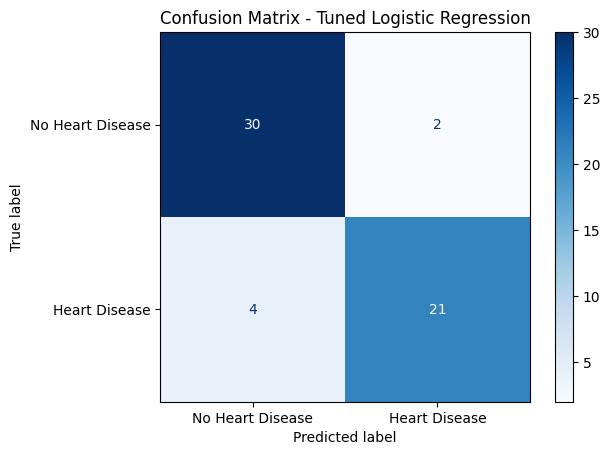

In [96]:
plot_confusion_matrix(
    'Logistic Regression',
    y_test,
    tuned_predictions['Logistic Regression'],
    'Tuned'
)

###ROC Curve

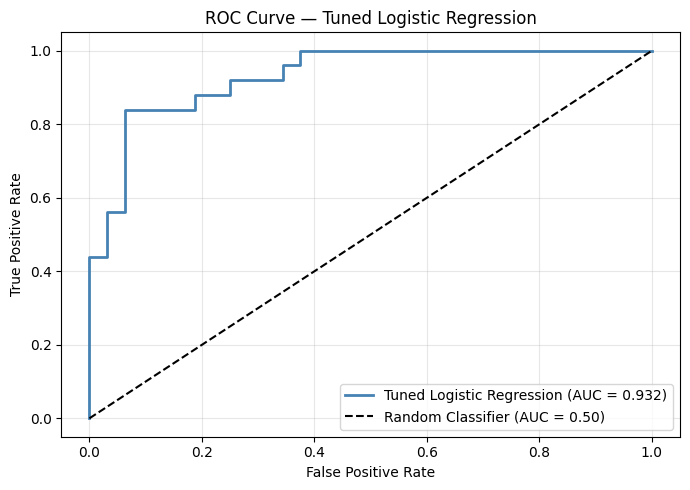

In [97]:
y_proba_lr_tuned = best_models['Logistic Regression'].predict_proba(X_test)[:, 1]
fpr_lr_t, tpr_lr_t, _ = roc_curve(y_test, y_proba_lr_tuned)
roc_auc_lr_t = auc(fpr_lr_t, tpr_lr_t)

plt.figure(figsize=(7, 5))
plt.plot(fpr_lr_t, tpr_lr_t, color='steelblue', lw=2, label=f'Tuned Logistic Regression (AUC = {roc_auc_lr_t:.3f})')
plt.plot([0, 1], [0, 1], 'k--', lw=1.5, label='Random Classifier (AUC = 0.50)')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Tuned Logistic Regression')
plt.legend(loc='lower right')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

##Model 02 - Random Forest Classifier

###Confusion Matrix

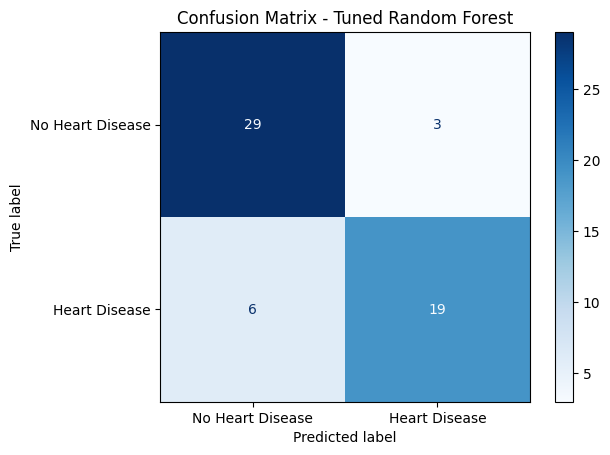

In [98]:
plot_confusion_matrix(
    'Random Forest',
    y_test,
    tuned_predictions['Random Forest'],
    'Tuned'
)

###ROC Curve

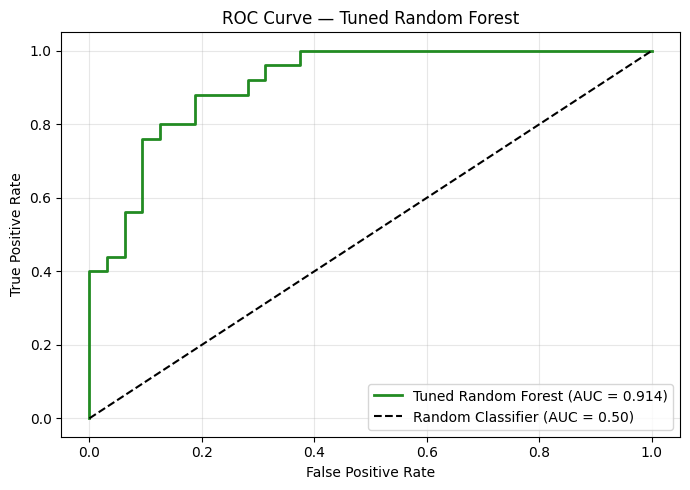

In [99]:
y_proba_rf_tuned = best_models['Random Forest'].predict_proba(X_test)[:, 1]
fpr_rf_t, tpr_rf_t, _ = roc_curve(y_test, y_proba_rf_tuned)
roc_auc_rf_t = auc(fpr_rf_t, tpr_rf_t)

plt.figure(figsize=(7, 5))
plt.plot(fpr_rf_t, tpr_rf_t, color='forestgreen', lw=2, label=f'Tuned Random Forest (AUC = {roc_auc_rf_t:.3f})')
plt.plot([0, 1], [0, 1], 'k--', lw=1.5, label='Random Classifier (AUC = 0.50)')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Tuned Random Forest')
plt.legend(loc='lower right')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

##Model 03 - Support Vector Machine

###Confusion Matrix

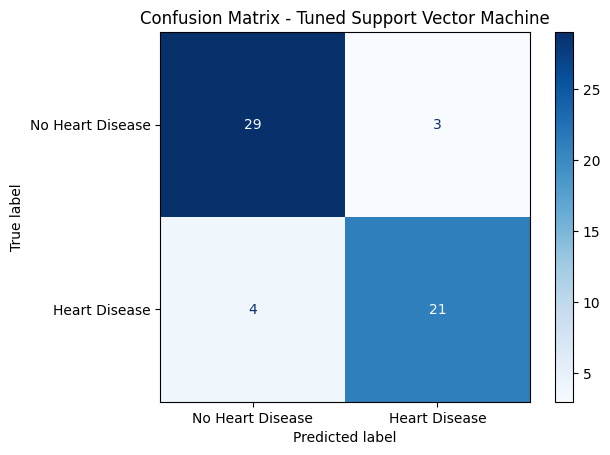

In [100]:
plot_confusion_matrix(
    'Support Vector Machine',
    y_test,
    tuned_predictions['Support Vector Machine'],
    'Tuned'
)

###ROC Curve

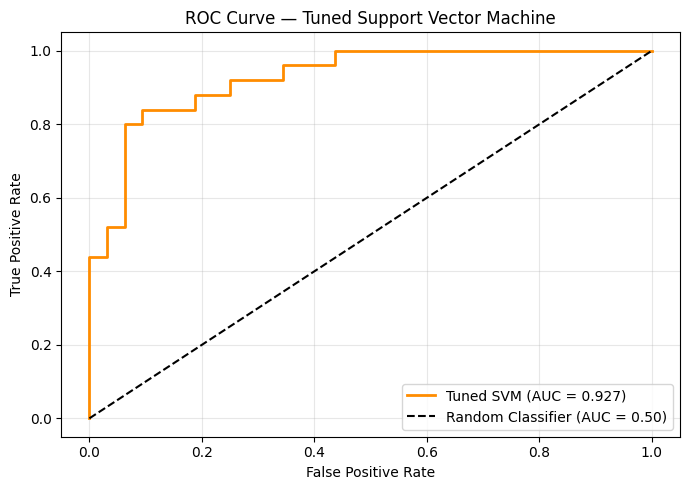

In [101]:
y_proba_svm_tuned = best_models['Support Vector Machine'].predict_proba(X_test)[:, 1]
fpr_svm_t, tpr_svm_t, _ = roc_curve(y_test, y_proba_svm_tuned)
roc_auc_svm_t = auc(fpr_svm_t, tpr_svm_t)

plt.figure(figsize=(7, 5))
plt.plot(fpr_svm_t, tpr_svm_t, color='darkorange', lw=2, label=f'Tuned SVM (AUC = {roc_auc_svm_t:.3f})')
plt.plot([0, 1], [0, 1], 'k--', lw=1.5, label='Random Classifier (AUC = 0.50)')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Tuned Support Vector Machine')
plt.legend(loc='lower right')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

##Model 04 - Decision Tree

###Confusion Matrix

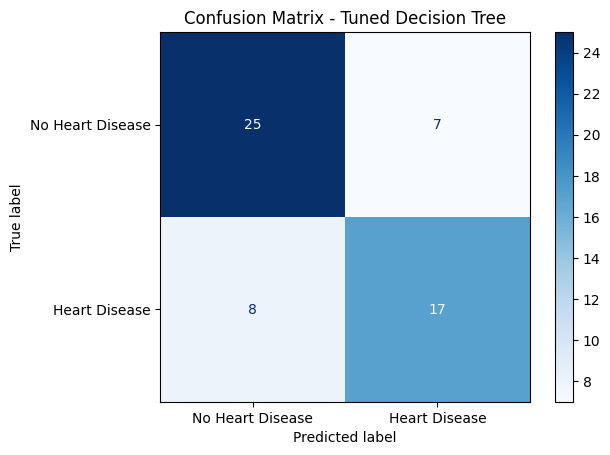

In [102]:
plot_confusion_matrix(
    'Decision Tree',
    y_test,
    tuned_predictions['Decision Tree'],
    'Tuned'
)

###ROC Curve

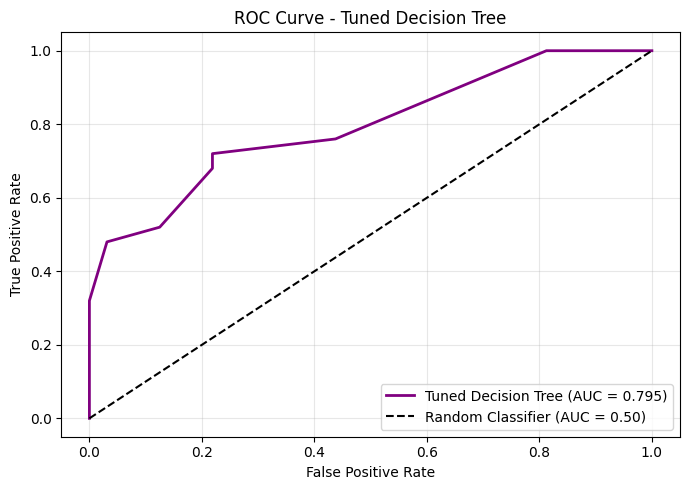

In [103]:
y_proba_dt_tuned = best_models['Decision Tree'].predict_proba(X_test)[:, 1]
fpr_dt_t, tpr_dt_t, _ = roc_curve(y_test, y_proba_dt_tuned)
roc_auc_dt_t = auc(fpr_dt_t, tpr_dt_t)

plt.figure(figsize=(7, 5))
plt.plot(fpr_dt_t, tpr_dt_t, color='purple', lw=2, label=f'Tuned Decision Tree (AUC = {roc_auc_dt_t:.3f})')
plt.plot([0, 1], [0, 1], 'k--', lw=1.5, label='Random Classifier (AUC = 0.50)')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Tuned Decision Tree')
plt.legend(loc='lower right')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

##Model 05 - AdaBoost Classifier

###Confusion Matrix

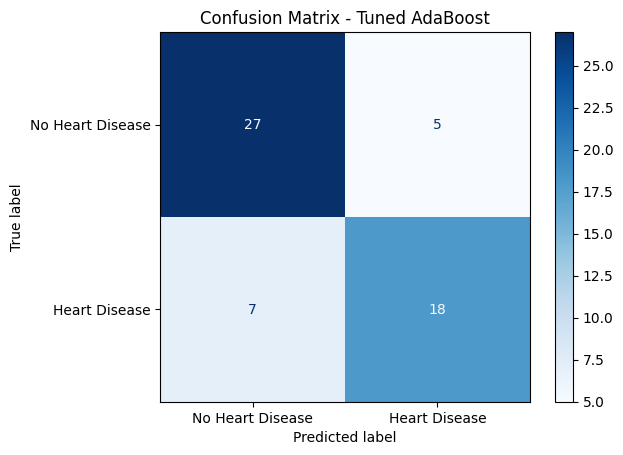

In [104]:
plot_confusion_matrix(
    'AdaBoost',
    y_test,
    tuned_predictions['AdaBoost'],
    'Tuned'
)

###ROC Curve

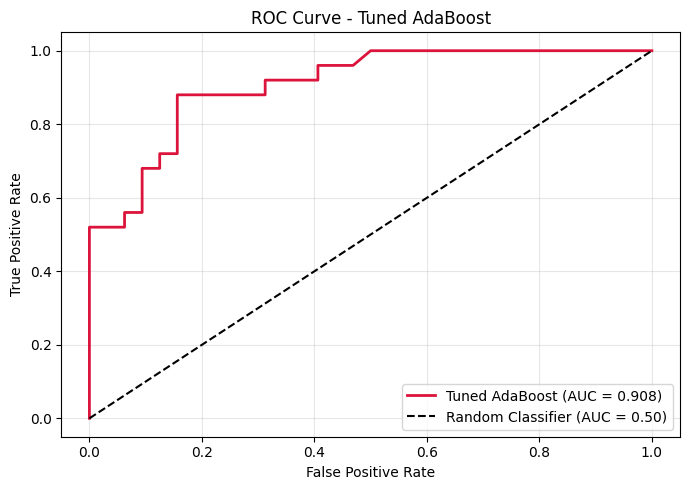

In [105]:
y_proba_ada_tuned = best_models['AdaBoost'].predict_proba(X_test)[:, 1]
fpr_ada_t, tpr_ada_t, _ = roc_curve(y_test, y_proba_ada_tuned)
roc_auc_ada_t = auc(fpr_ada_t, tpr_ada_t)

plt.figure(figsize=(7, 5))
plt.plot(fpr_ada_t, tpr_ada_t, color='crimson', lw=2, label=f'Tuned AdaBoost (AUC = {roc_auc_ada_t:.3f})')
plt.plot([0, 1], [0, 1], 'k--', lw=1.5, label='Random Classifier (AUC = 0.50)')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Tuned AdaBoost')
plt.legend(loc='lower right')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

##Model 06 - XGBoost Classifier

###Confusion Matrix

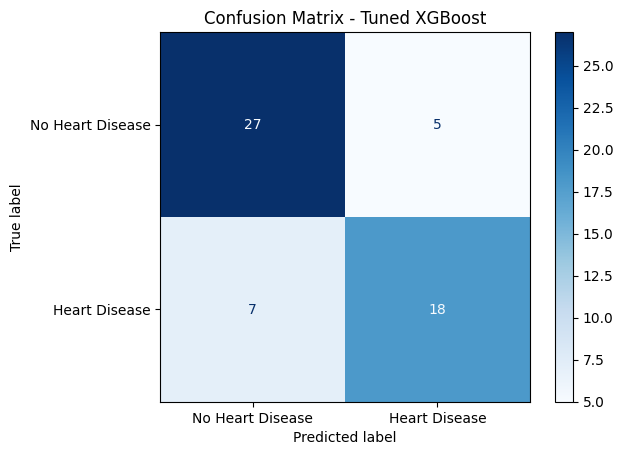

In [106]:
plot_confusion_matrix(
    'XGBoost',
    y_test,
    tuned_predictions['XGBoost'],
    'Tuned'
)

###ROC Curve

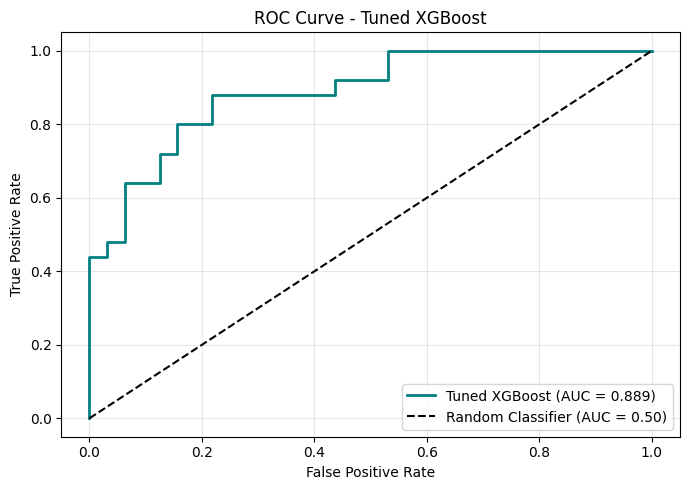

In [107]:
y_proba_xgb_tuned = best_models['XGBoost'].predict_proba(X_test)[:, 1]
fpr_xgb_t, tpr_xgb_t, _ = roc_curve(y_test, y_proba_xgb_tuned)
roc_auc_xgb_t = auc(fpr_xgb_t, tpr_xgb_t)

plt.figure(figsize=(7, 5))
plt.plot(fpr_xgb_t, tpr_xgb_t, color='teal', lw=2, label=f'Tuned XGBoost (AUC = {roc_auc_xgb_t:.3f})')
plt.plot([0, 1], [0, 1], 'k--', lw=1.5, label='Random Classifier (AUC = 0.50)')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Tuned XGBoost')
plt.legend(loc='lower right')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Part 5

## Visualizations

### Feature Importance for Tree-Based Models

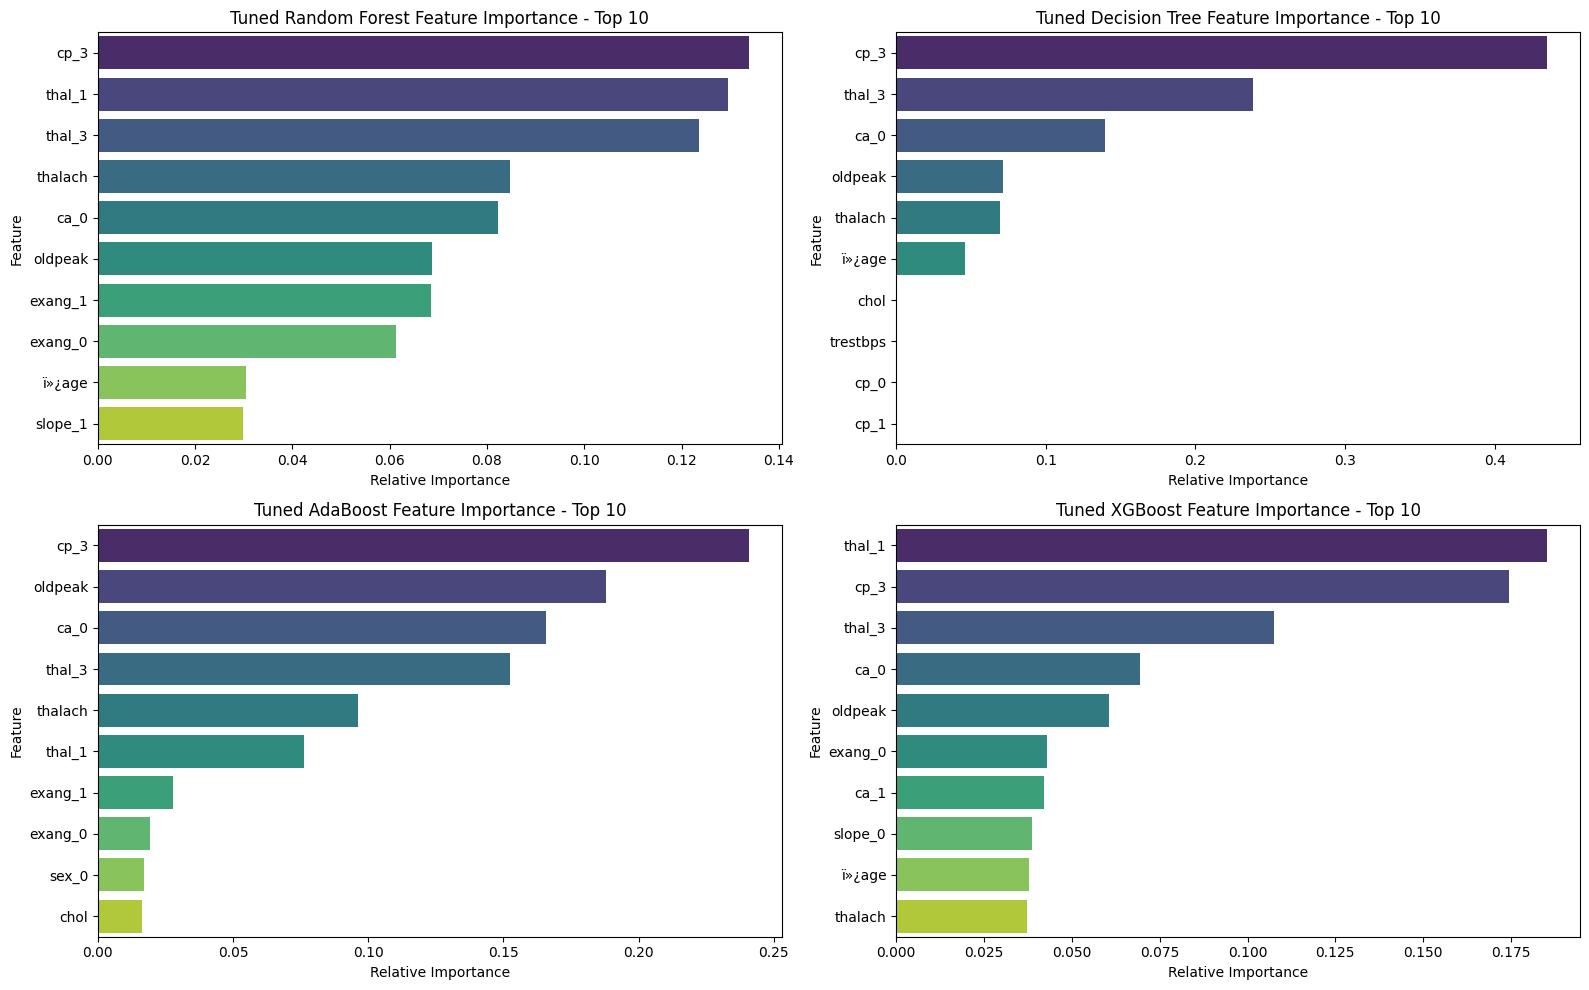

In [108]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

feature_names = X_train.columns

tree_models = {
    'Random Forest': best_models['Random Forest'].feature_importances_,
    'Decision Tree': best_models['Decision Tree'].feature_importances_,
    'AdaBoost': best_models['AdaBoost'].feature_importances_,
    'XGBoost': best_models['XGBoost'].feature_importances_
}

plt.figure(figsize=(16, 10))

for i, (model_name, importances) in enumerate(tree_models.items()):
    feature_importance_df = pd.DataFrame({
        'Feature': feature_names,
        'Importance': importances
    }).sort_values(by='Importance', ascending=False)

    plt.subplot(2, 2, i + 1)

    sns.barplot(
        x='Importance',
        y='Feature',
        hue='Feature',
        data=feature_importance_df.head(10),
        palette='viridis',
        legend=False
    )

    plt.title(f'Tuned {model_name} Feature Importance - Top 10')
    plt.xlabel('Relative Importance')
    plt.ylabel('Feature')

plt.tight_layout()
plt.show()

### ROC Curves for All Models

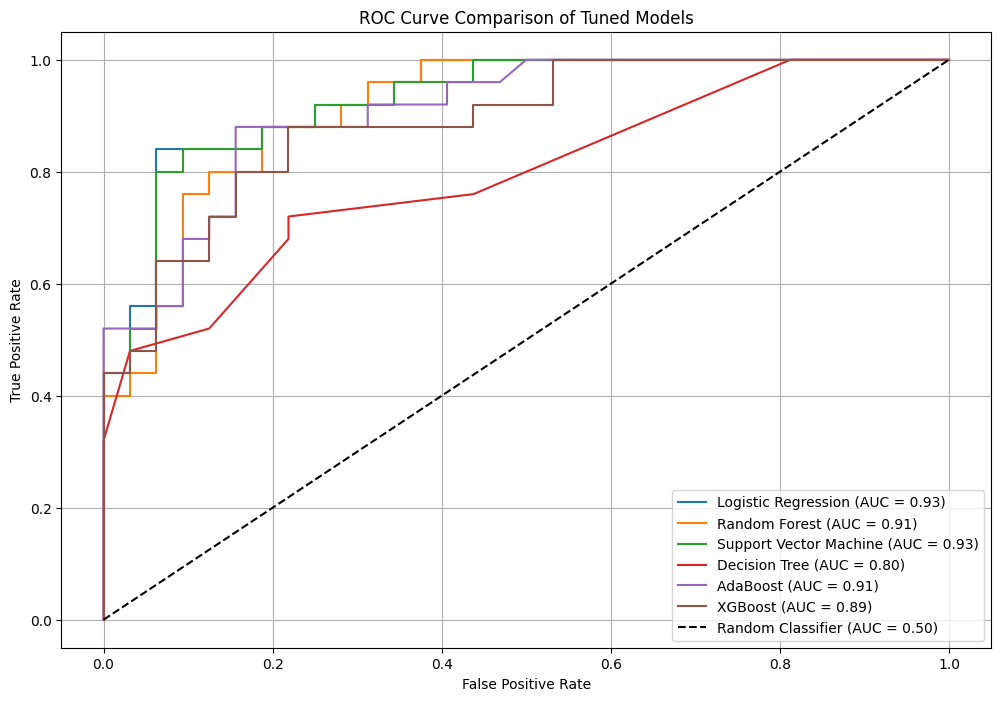

In [109]:
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 8))

models_for_roc = {
    'Logistic Regression': best_models['Logistic Regression'].predict_proba(X_test)[:, 1],
    'Random Forest': best_models['Random Forest'].predict_proba(X_test)[:, 1],
    'Support Vector Machine': best_models['Support Vector Machine'].predict_proba(X_test)[:, 1],
    'Decision Tree': best_models['Decision Tree'].predict_proba(X_test)[:, 1],
    'AdaBoost': best_models['AdaBoost'].predict_proba(X_test)[:, 1],
    'XGBoost': best_models['XGBoost'].predict_proba(X_test)[:, 1]
}

for model_name, y_pred_proba in models_for_roc.items():
    fpr, tpr, _ = roc_curve(y_test, y_pred_proba)
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f'{model_name} (AUC = {roc_auc:.2f})')

plt.plot([0, 1], [0, 1], 'k--', label='Random Classifier (AUC = 0.50)')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve Comparison of Tuned Models')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

### Comparison of Model Performance

Tuned Model Ranking Considering All Five Metrics:


,Accuracy,Precision,Recall,F1-Score,ROC-AUC,Average Rank
Logistic Regression,0.8947,0.9130,0.84,0.8750,0.9325,1.1
Support Vector Machine,0.8772,0.8750,0.84,0.8571,0.9275,1.9
Random Forest,0.8421,0.8636,0.76,0.8085,0.9138,3.0
AdaBoost,0.7895,0.7826,0.72,0.7500,0.9081,4.4
XGBoost,0.7895,0.7826,0.72,0.7500,0.8888,4.6
Decision Tree,0.7368,0.7083,0.68,0.6939,0.7950,6.0


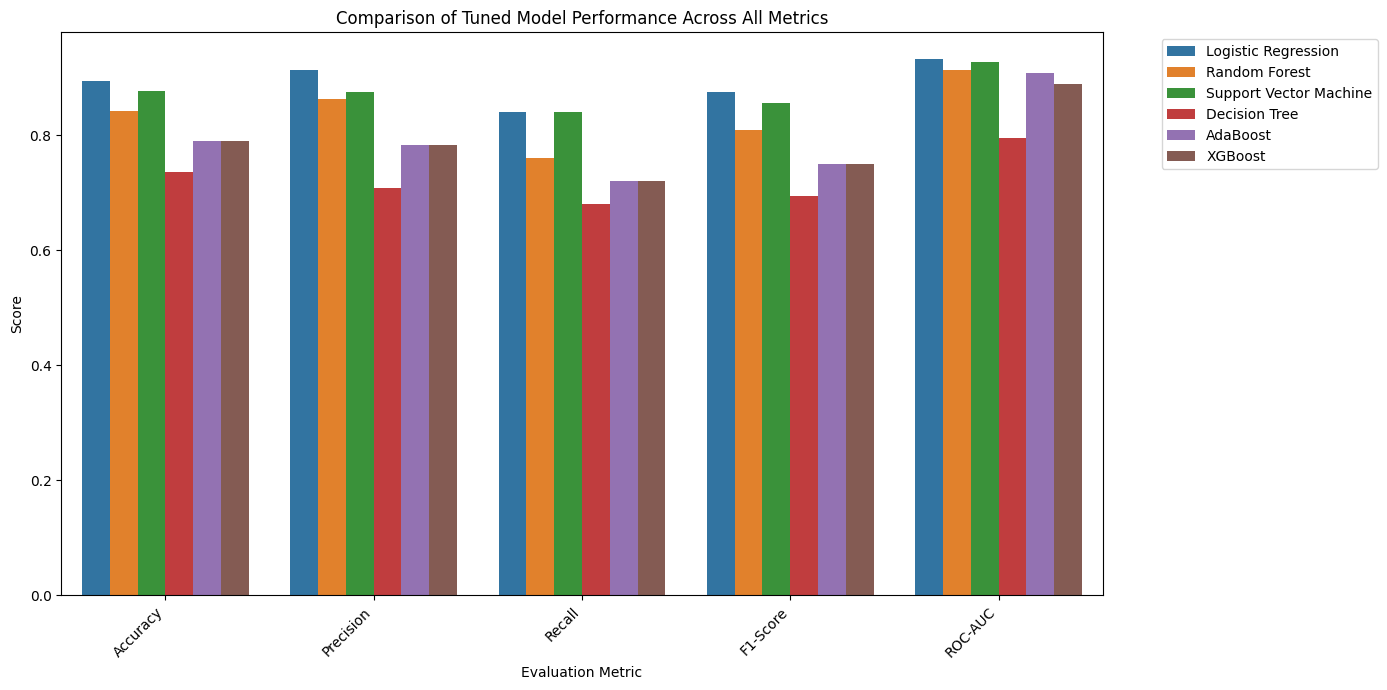

In [110]:
import matplotlib.pyplot as plt
import seaborn as sns

# Create tuned model performance table
metrics_df = pd.DataFrame.from_dict(tuned_metrics, orient='index')
metrics_df = metrics_df.round(4)

# Rank models by all five evaluation metrics equally
ranked_models = metrics_df.copy()
ranked_models['Average Rank'] = ranked_models[
    ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC']
].rank(ascending=False).mean(axis=1)

ranked_models = ranked_models.sort_values(by='Average Rank')

print("Tuned Model Ranking Considering All Five Metrics:")
display(ranked_models)

best_model_name = ranked_models.index[0]

# Convert metrics table into long format for plotting
metrics_melted = metrics_df.reset_index().rename(columns={'index': 'Model'})
metrics_melted = metrics_melted.melt(
    id_vars='Model',
    var_name='Metric',
    value_name='Score'
)

plt.figure(figsize=(14, 7))

sns.barplot(
    x='Metric',
    y='Score',
    hue='Model',
    data=metrics_melted,
    palette='tab10'
)

plt.title('Comparison of Tuned Model Performance Across All Metrics')
plt.ylabel('Score')
plt.xlabel('Evaluation Metric')
plt.xticks(rotation=45, ha='right')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

#Artifical Neural Network

##ANN Imports

In [111]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, BatchNormalization, Input
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.regularizers import l2
from tensorflow.keras.optimizers import Adam

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, classification_report, confusion_matrix,
    ConfusionMatrixDisplay, RocCurveDisplay, roc_curve, auc
)

from sklearn.inspection import permutation_importance

import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import seaborn as sns

tf.random.set_seed(42)
np.random.seed(42)

##Create Validation Data for ANN

In [112]:
X_train_ann, X_val_ann, y_train_ann, y_val_ann = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

print("Training shape   :", X_train_ann.shape)
print("Validation shape :", X_val_ann.shape)
print("Test shape       :", X_test.shape)

Training shape   : (181, 28)
Validation shape : (46, 28)
Test shape       : (57, 28)


##Baseline ANN

###Build Baseline ANN

In [113]:
baseline_ann_model = Sequential([
    Input(shape=(X_train_ann.shape[1],)),

    # Simple baseline network for fair comparison before ANN tuning
    Dense(32, activation='relu'),
    Dropout(0.20),

    Dense(16, activation='relu'),
    Dropout(0.10),

    Dense(1, activation='sigmoid')
])

baseline_ann_model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='binary_crossentropy',
    metrics=[
        'accuracy',
        tf.keras.metrics.AUC(name='auc')
    ]
)

baseline_ann_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │           928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,473 (5.75 KB)

 Trainable params: 1,473 (5.75 KB)

 Non-trainable params: 0 (0.00 B)

###Baseline ANN Callbacks

In [114]:
early_stop_baseline = EarlyStopping(
    monitor='val_loss',
    patience=15,
    restore_best_weights=True,
    verbose=1
)

###Train Baseline ANN

In [115]:
history_baseline_ann = baseline_ann_model.fit(
    X_train_ann,
    y_train_ann,
    validation_data=(X_val_ann, y_val_ann),
    epochs=120,
    batch_size=16,
    callbacks=[early_stop_baseline],
    verbose=1
)

Epoch 1/120
12/12 ━━━━━━━━━━━━━━━━━━━━ 2s 36ms/step - accuracy: 0.3591 - auc: 0.3011 - loss: 0.8156 - val_accuracy: 0.3261 - val_auc: 0.2365 - val_loss: 0.7599
Epoch 2/120
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.4254 - auc: 0.4270 - loss: 0.7384 - val_accuracy: 0.5435 - val_auc: 0.5317 - val_loss: 0.7012
Epoch 3/120
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.4807 - auc: 0.5340 - loss: 0.7034 - val_accuracy: 0.6522 - val_auc: 0.7269 - val_loss: 0.6636
Epoch 4/120
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.5635 - auc: 0.6239 - loss: 0.6779 - val_accuracy: 0.6957 - val_auc: 0.8125 - val_loss: 0.6328
Epoch 5/120
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.6961 - auc: 0.7485 - loss: 0.6412 - val_accuracy: 0.7391 - val_auc: 0.8683 - val_loss: 0.6035
Epoch 6/120
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.7072 - auc: 0.7560 - loss: 0.6246 - val_accuracy: 0.8043 - val_auc: 0.8942 - val_loss: 0.5736
Epoch 7/120
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms

###Baseline ANN Predictions

In [116]:
y_prob_ann_baseline = baseline_ann_model.predict(X_test).ravel()
y_pred_ann_baseline = (y_prob_ann_baseline >= 0.5).astype("int32")

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step


###Baseline ANN Evaluation

In [117]:
accuracy_ann_baseline = accuracy_score(y_test, y_pred_ann_baseline)
precision_ann_baseline = precision_score(y_test, y_pred_ann_baseline, zero_division=0)
recall_ann_baseline = recall_score(y_test, y_pred_ann_baseline, zero_division=0)
f1_ann_baseline = f1_score(y_test, y_pred_ann_baseline, zero_division=0)
roc_auc_ann_baseline = roc_auc_score(y_test, y_prob_ann_baseline)

print("Baseline ANN Results:")
print(classification_report(y_test, y_pred_ann_baseline))

print("Accuracy :", round(accuracy_ann_baseline, 4))
print("Precision:", round(precision_ann_baseline, 4))
print("Recall   :", round(recall_ann_baseline, 4))
print("F1-Score :", round(f1_ann_baseline, 4))
print("ROC-AUC  :", round(roc_auc_ann_baseline, 4))

ann_baseline_metrics = {
    'Accuracy': accuracy_ann_baseline,
    'Precision': precision_ann_baseline,
    'Recall': recall_ann_baseline,
    'F1-Score': f1_ann_baseline,
    'ROC-AUC': roc_auc_ann_baseline
}

Baseline ANN Results:
              precision    recall  f1-score   support

           0       0.88      0.91      0.89        32
           1       0.88      0.84      0.86        25

    accuracy                           0.88        57
   macro avg       0.88      0.87      0.87        57
weighted avg       0.88      0.88      0.88        57

Accuracy : 0.8772
Precision: 0.875
Recall   : 0.84
F1-Score : 0.8571
ROC-AUC  : 0.93


###Baseline ANN Confusion Matrix

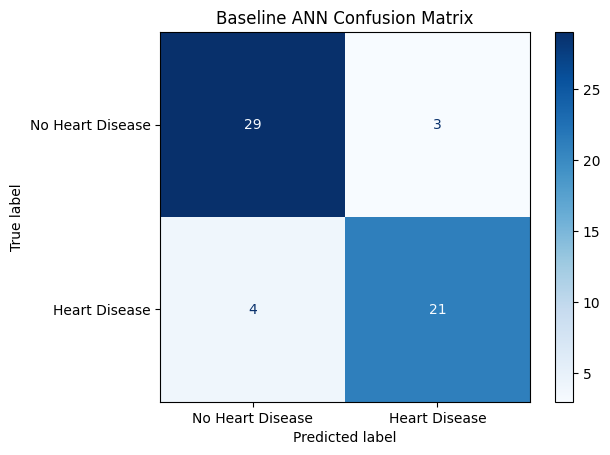

In [118]:
cm_ann_baseline = confusion_matrix(y_test, y_pred_ann_baseline)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_ann_baseline,
    display_labels=['No Heart Disease', 'Heart Disease']
)

disp.plot(cmap='Blues')
plt.title("Baseline ANN Confusion Matrix")
plt.show()

##Hyperparameter Tuning for ANN

###Build ANN Function for Tuning

In [119]:
def build_ann_model(hidden_layers, neurons, dropout_rate, learning_rate, l2_rate):
    model = Sequential()
    model.add(Input(shape=(X_train_ann.shape[1],)))

    # Hidden layers are tuned because deeper ANN models can overfit small datasets
    for i in range(hidden_layers):
        model.add(Dense(
            max(neurons // (2 ** i), 8),
            activation='relu',
            kernel_regularizer=l2(l2_rate)
        ))
        model.add(BatchNormalization())
        model.add(Dropout(dropout_rate))

    model.add(Dense(1, activation='sigmoid'))

    model.compile(
        optimizer=Adam(learning_rate=learning_rate),
        loss='binary_crossentropy',
        metrics=[
            'accuracy',
            tf.keras.metrics.AUC(name='auc')
        ]
    )

    return model

###ANN Tuning Round 1 - Hidden Layer Selection

####Test Different Hideen Layer Architecture

In [120]:
ann_round1_results = []

ann_round1_grid = [
    # 1 hidden layer models
    {'hidden_layers': 1, 'neurons': 16, 'dropout_rate': 0.10, 'learning_rate': 0.001,  'l2_rate': 1e-4},
    {'hidden_layers': 1, 'neurons': 32, 'dropout_rate': 0.20, 'learning_rate': 0.001,  'l2_rate': 1e-4},
    {'hidden_layers': 1, 'neurons': 48, 'dropout_rate': 0.20, 'learning_rate': 0.001,  'l2_rate': 1e-4},
    {'hidden_layers': 1, 'neurons': 64, 'dropout_rate': 0.25, 'learning_rate': 0.001,  'l2_rate': 1e-4},

    # 2 hidden layer models
    {'hidden_layers': 2, 'neurons': 32, 'dropout_rate': 0.20, 'learning_rate': 0.001,  'l2_rate': 1e-4},
    {'hidden_layers': 2, 'neurons': 48, 'dropout_rate': 0.25, 'learning_rate': 0.001,  'l2_rate': 1e-4},
    {'hidden_layers': 2, 'neurons': 64, 'dropout_rate': 0.25, 'learning_rate': 0.001,  'l2_rate': 1e-4},
    {'hidden_layers': 2, 'neurons': 64, 'dropout_rate': 0.30, 'learning_rate': 0.0007, 'l2_rate': 1e-4},

    # 3 hidden layer models
    {'hidden_layers': 3, 'neurons': 48, 'dropout_rate': 0.30, 'learning_rate': 0.0007, 'l2_rate': 1e-4},
    {'hidden_layers': 3, 'neurons': 64, 'dropout_rate': 0.30, 'learning_rate': 0.0007, 'l2_rate': 1e-4}
]

for params in ann_round1_grid:
    print("\nTesting ANN Round 1 Parameters:", params)

    temp_ann_model = build_ann_model(**params)

    early_stop = EarlyStopping(
        monitor='val_loss',
        patience=15,
        restore_best_weights=True,
        verbose=0
    )

    reduce_lr = ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=5,
        min_lr=1e-6,
        verbose=0
    )

    history_temp = temp_ann_model.fit(
        X_train_ann,
        y_train_ann,
        validation_data=(X_val_ann, y_val_ann),
        epochs=120,
        batch_size=16,
        callbacks=[early_stop, reduce_lr],
        verbose=0
    )

    val_prob = temp_ann_model.predict(X_val_ann, verbose=0).ravel()
    val_pred = (val_prob >= 0.5).astype("int32")

    ann_round1_results.append({
        'Hidden Layers': params['hidden_layers'],
        'Neurons': params['neurons'],
        'Dropout': params['dropout_rate'],
        'Learning Rate': params['learning_rate'],
        'L2 Rate': params['l2_rate'],
        'Validation Accuracy': accuracy_score(y_val_ann, val_pred),
        'Validation Precision': precision_score(y_val_ann, val_pred, zero_division=0),
        'Validation Recall': recall_score(y_val_ann, val_pred, zero_division=0),
        'Validation F1-Score': f1_score(y_val_ann, val_pred, zero_division=0),
        'Validation ROC-AUC': roc_auc_score(y_val_ann, val_prob),
        'Model': temp_ann_model,
        'History': history_temp
    })

ann_round1_df = pd.DataFrame(ann_round1_results).drop(columns=['Model', 'History'])
display(ann_round1_df)


Testing ANN Round 1 Parameters: {'hidden_layers': 1, 'neurons': 16, 'dropout_rate': 0.1, 'learning_rate': 0.001, 'l2_rate': 0.0001}

Testing ANN Round 1 Parameters: {'hidden_layers': 1, 'neurons': 32, 'dropout_rate': 0.2, 'learning_rate': 0.001, 'l2_rate': 0.0001}



Testing ANN Round 1 Parameters: {'hidden_layers': 1, 'neurons': 48, 'dropout_rate': 0.2, 'learning_rate': 0.001, 'l2_rate': 0.0001}

Testing ANN Round 1 Parameters: {'hidden_layers': 1, 'neurons': 64, 'dropout_rate': 0.25, 'learning_rate': 0.001, 'l2_rate': 0.0001}

Testing ANN Round 1 Parameters: {'hidden_layers': 2, 'neurons': 32, 'dropout_rate': 0.2, 'learning_rate': 0.001, 'l2_rate': 0.0001}

Testing ANN Round 1 Parameters: {'hidden_layers': 2, 'neurons': 48, 'dropout_rate': 0.25, 'learning_rate': 0.001, 'l2_rate': 0.0001}

Testing ANN Round 1 Parameters: {'hidden_layers': 2, 'neurons': 64, 'dropout_rate': 0.25, 'learning_rate': 0.001, 'l2_rate': 0.0001}

Testing ANN Round 1 Parameters: {'hidden_layers': 2, 'neurons': 64, 'dropout_rate': 0.3, 'learning_rate': 0.0007, 'l2_rate': 0.0001}

Testing ANN Round 1 Parameters: {'hidden_layers': 3, 'neurons': 48, 'dropout_rate': 0.3, 'learning_rate': 0.0007, 'l2_rate': 0.0001}

Testing ANN Round 1 Parameters: {'hidden_layers': 3, 'neurons':

,Hidden Layers,Neurons,Dropout,Learning Rate,L2 Rate,Validation Accuracy,Validation Precision,Validation Recall,Validation F1-Score,Validation ROC-AUC
0,1,16,0.10,0.0010,0.0001,0.869565,0.791667,0.95,0.863636,0.925000
1,1,32,0.20,0.0010,0.0001,0.847826,0.809524,0.85,0.829268,0.919231
2,1,48,0.20,0.0010,0.0001,0.847826,0.782609,0.90,0.837209,0.936538
3,1,64,0.25,0.0010,0.0001,0.891304,0.857143,0.90,0.878049,0.936538
4,2,32,0.20,0.0010,0.0001,0.891304,0.857143,0.90,0.878049,0.934615
5,2,48,0.25,0.0010,0.0001,0.847826,0.782609,0.90,0.837209,0.944231
6,2,64,0.25,0.0010,0.0001,0.847826,0.760000,0.95,0.844444,0.946154
7,2,64,0.30,0.0007,0.0001,0.826087,0.800000,0.80,0.800000,0.940385
8,3,48,0.30,0.0007,0.0001,0.891304,0.857143,0.90,0.878049,0.942308
9,3,64,0.30,0.0007,0.0001,0.891304,0.894737,0.85,0.871795,0.944231


####Select Best ANN from Round 1

In [121]:
ann_round1_ranked = ann_round1_df.copy()

# All five validation metrics are considered equally
ann_round1_ranked['Average Rank'] = ann_round1_ranked[
    [
        'Validation Accuracy',
        'Validation Precision',
        'Validation Recall',
        'Validation F1-Score',
        'Validation ROC-AUC'
    ]
].rank(ascending=False).mean(axis=1)

ann_round1_ranked = ann_round1_ranked.sort_values(by='Average Rank')

display(ann_round1_ranked)

best_round1_index = ann_round1_ranked.index[0]

print("Best ANN Architecture from Round 1:")
display(ann_round1_ranked.loc[[best_round1_index]])

,Hidden Layers,Neurons,Dropout,Learning Rate,L2 Rate,Validation Accuracy,Validation Precision,Validation Recall,Validation F1-Score,Validation ROC-AUC,Average Rank
8,3,48,0.30,0.0007,0.0001,0.891304,0.857143,0.90,0.878049,0.942308,3.3
9,3,64,0.30,0.0007,0.0001,0.891304,0.894737,0.85,0.871795,0.944231,3.7
3,1,64,0.25,0.0010,0.0001,0.891304,0.857143,0.90,0.878049,0.936538,3.8
4,2,32,0.20,0.0010,0.0001,0.891304,0.857143,0.90,0.878049,0.934615,4.1
6,2,64,0.25,0.0010,0.0001,0.847826,0.760000,0.95,0.844444,0.946154,5.2
0,1,16,0.10,0.0010,0.0001,0.869565,0.791667,0.95,0.863636,0.925000,5.5
5,2,48,0.25,0.0010,0.0001,0.847826,0.782609,0.90,0.837209,0.944231,6.2
2,1,48,0.20,0.0010,0.0001,0.847826,0.782609,0.90,0.837209,0.936538,7.0
1,1,32,0.20,0.0010,0.0001,0.847826,0.809524,0.85,0.829268,0.919231,8.0
7,2,64,0.30,0.0007,0.0001,0.826087,0.800000,0.80,0.800000,0.940385,8.2


Best ANN Architecture from Round 1:


,Hidden Layers,Neurons,Dropout,Learning Rate,L2 Rate,Validation Accuracy,Validation Precision,Validation Recall,Validation F1-Score,Validation ROC-AUC,Average Rank
8,3,48,0.3,0.0007,0.0001,0.891304,0.857143,0.9,0.878049,0.942308,3.3


###ANN Tuning Round 2 — Fine-Tuning Around Best Architecture

####Fine-Tune Best ANN Structure

In [122]:
ann_round2_results = []

ann_round2_grid = [
    {'hidden_layers': 1, 'neurons': 24, 'dropout_rate': 0.15, 'learning_rate': 0.0010, 'l2_rate': 1e-4},
    {'hidden_layers': 1, 'neurons': 32, 'dropout_rate': 0.15, 'learning_rate': 0.0010, 'l2_rate': 1e-4},
    {'hidden_layers': 1, 'neurons': 32, 'dropout_rate': 0.20, 'learning_rate': 0.0010, 'l2_rate': 1e-4},
    {'hidden_layers': 1, 'neurons': 32, 'dropout_rate': 0.25, 'learning_rate': 0.0010, 'l2_rate': 1e-4},
    {'hidden_layers': 1, 'neurons': 40, 'dropout_rate': 0.20, 'learning_rate': 0.0010, 'l2_rate': 1e-4},
    {'hidden_layers': 1, 'neurons': 48, 'dropout_rate': 0.20, 'learning_rate': 0.0010, 'l2_rate': 1e-4},
    {'hidden_layers': 1, 'neurons': 32, 'dropout_rate': 0.20, 'learning_rate': 0.0007, 'l2_rate': 1e-4},
    {'hidden_layers': 1, 'neurons': 32, 'dropout_rate': 0.20, 'learning_rate': 0.0010, 'l2_rate': 5e-4}
]

for params in ann_round2_grid:
    print("\nTesting ANN Round 2 Parameters:", params)

    temp_ann_model = build_ann_model(**params)

    early_stop = EarlyStopping(
        monitor='val_loss',
        patience=10,
        restore_best_weights=True,
        verbose=0
    )

    reduce_lr = ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=4,
        min_lr=1e-6,
        verbose=0
    )

    history_temp = temp_ann_model.fit(
        X_train_ann,
        y_train_ann,
        validation_data=(X_val_ann, y_val_ann),
        epochs=100,
        batch_size=16,
        callbacks=[early_stop, reduce_lr],
        verbose=0
    )

    val_prob = temp_ann_model.predict(X_val_ann, verbose=0).ravel()
    val_pred = (val_prob >= 0.5).astype("int32")

    ann_round2_results.append({
        'Hidden Layers': params['hidden_layers'],
        'Neurons': params['neurons'],
        'Dropout': params['dropout_rate'],
        'Learning Rate': params['learning_rate'],
        'L2 Rate': params['l2_rate'],
        'Validation Accuracy': accuracy_score(y_val_ann, val_pred),
        'Validation Precision': precision_score(y_val_ann, val_pred, zero_division=0),
        'Validation Recall': recall_score(y_val_ann, val_pred, zero_division=0),
        'Validation F1-Score': f1_score(y_val_ann, val_pred, zero_division=0),
        'Validation ROC-AUC': roc_auc_score(y_val_ann, val_prob),
        'Model': temp_ann_model,
        'History': history_temp
    })

ann_round2_df = pd.DataFrame(ann_round2_results).drop(columns=['Model', 'History'])
display(ann_round2_df)


Testing ANN Round 2 Parameters: {'hidden_layers': 1, 'neurons': 24, 'dropout_rate': 0.15, 'learning_rate': 0.001, 'l2_rate': 0.0001}

Testing ANN Round 2 Parameters: {'hidden_layers': 1, 'neurons': 32, 'dropout_rate': 0.15, 'learning_rate': 0.001, 'l2_rate': 0.0001}

Testing ANN Round 2 Parameters: {'hidden_layers': 1, 'neurons': 32, 'dropout_rate': 0.2, 'learning_rate': 0.001, 'l2_rate': 0.0001}

Testing ANN Round 2 Parameters: {'hidden_layers': 1, 'neurons': 32, 'dropout_rate': 0.25, 'learning_rate': 0.001, 'l2_rate': 0.0001}

Testing ANN Round 2 Parameters: {'hidden_layers': 1, 'neurons': 40, 'dropout_rate': 0.2, 'learning_rate': 0.001, 'l2_rate': 0.0001}

Testing ANN Round 2 Parameters: {'hidden_layers': 1, 'neurons': 48, 'dropout_rate': 0.2, 'learning_rate': 0.001, 'l2_rate': 0.0001}

Testing ANN Round 2 Parameters: {'hidden_layers': 1, 'neurons': 32, 'dropout_rate': 0.2, 'learning_rate': 0.0007, 'l2_rate': 0.0001}

Testing ANN Round 2 Parameters: {'hidden_layers': 1, 'neurons': 

,Hidden Layers,Neurons,Dropout,Learning Rate,L2 Rate,Validation Accuracy,Validation Precision,Validation Recall,Validation F1-Score,Validation ROC-AUC
0,1,24,0.15,0.0010,0.0001,0.826087,0.800000,0.80,0.800000,0.911538
1,1,32,0.15,0.0010,0.0001,0.869565,0.818182,0.90,0.857143,0.942308
2,1,32,0.20,0.0010,0.0001,0.826087,0.772727,0.85,0.809524,0.923077
3,1,32,0.25,0.0010,0.0001,0.869565,0.850000,0.85,0.850000,0.946154
4,1,40,0.20,0.0010,0.0001,0.869565,0.818182,0.90,0.857143,0.946154
5,1,48,0.20,0.0010,0.0001,0.869565,0.818182,0.90,0.857143,0.932692
6,1,32,0.20,0.0007,0.0001,0.913043,0.900000,0.90,0.900000,0.944231
7,1,32,0.20,0.0010,0.0005,0.847826,0.809524,0.85,0.829268,0.913462


####Select Final Tuned ANN

In [123]:
ann_round2_ranked = ann_round2_df.copy()

ann_round2_ranked['Average Rank'] = ann_round2_ranked[
    [
        'Validation Accuracy',
        'Validation Precision',
        'Validation Recall',
        'Validation F1-Score',
        'Validation ROC-AUC'
    ]
].rank(ascending=False).mean(axis=1)

ann_round2_ranked = ann_round2_ranked.sort_values(by='Average Rank')

display(ann_round2_ranked)

best_ann_index = ann_round2_ranked.index[0]

best_ann_model = ann_round2_results[best_ann_index]['Model']
best_ann_history = ann_round2_results[best_ann_index]['History']

print("Final Tuned ANN Parameters:")
display(ann_round2_ranked.loc[[best_ann_index]])

,Hidden Layers,Neurons,Dropout,Learning Rate,L2 Rate,Validation Accuracy,Validation Precision,Validation Recall,Validation F1-Score,Validation ROC-AUC,Average Rank
6,1,32,0.20,0.0007,0.0001,0.913043,0.900000,0.90,0.900000,0.944231,1.7
4,1,40,0.20,0.0010,0.0001,0.869565,0.818182,0.90,0.857143,0.946154,2.9
1,1,32,0.15,0.0010,0.0001,0.869565,0.818182,0.90,0.857143,0.942308,3.4
3,1,32,0.25,0.0010,0.0001,0.869565,0.850000,0.85,0.850000,0.946154,3.6
5,1,48,0.20,0.0010,0.0001,0.869565,0.818182,0.90,0.857143,0.932692,3.6
7,1,32,0.20,0.0010,0.0005,0.847826,0.809524,0.85,0.829268,0.913462,6.2
2,1,32,0.20,0.0010,0.0001,0.826087,0.772727,0.85,0.809524,0.923077,6.9
0,1,24,0.15,0.0010,0.0001,0.826087,0.800000,0.80,0.800000,0.911538,7.7


Final Tuned ANN Parameters:


,Hidden Layers,Neurons,Dropout,Learning Rate,L2 Rate,Validation Accuracy,Validation Precision,Validation Recall,Validation F1-Score,Validation ROC-AUC,Average Rank
6,1,32,0.2,0.0007,0.0001,0.913043,0.9,0.9,0.9,0.944231,1.7


###Final Tuned ANN Evaluation

####Final Tuned ANN Predictions

In [124]:
y_prob_ann = best_ann_model.predict(X_test).ravel()
y_pred_ann = (y_prob_ann >= 0.5).astype("int32")

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step


####Final Tuned ANN Evaluation

In [125]:
accuracy_ann = accuracy_score(y_test, y_pred_ann)
precision_ann = precision_score(y_test, y_pred_ann, zero_division=0)
recall_ann = recall_score(y_test, y_pred_ann, zero_division=0)
f1_ann = f1_score(y_test, y_pred_ann, zero_division=0)
roc_auc_ann = roc_auc_score(y_test, y_prob_ann)

print("Final Tuned ANN Results:")
print(classification_report(y_test, y_pred_ann))

print("Accuracy :", round(accuracy_ann, 4))
print("Precision:", round(precision_ann, 4))
print("Recall   :", round(recall_ann, 4))
print("F1-Score :", round(f1_ann, 4))
print("ROC-AUC  :", round(roc_auc_ann, 4))

ann_tuned_metrics = {
    'Accuracy': accuracy_ann,
    'Precision': precision_ann,
    'Recall': recall_ann,
    'F1-Score': f1_ann,
    'ROC-AUC': roc_auc_ann
}

Final Tuned ANN Results:
              precision    recall  f1-score   support

           0       0.88      0.94      0.91        32
           1       0.91      0.84      0.88        25

    accuracy                           0.89        57
   macro avg       0.90      0.89      0.89        57
weighted avg       0.90      0.89      0.89        57

Accuracy : 0.8947
Precision: 0.913
Recall   : 0.84
F1-Score : 0.875
ROC-AUC  : 0.925


####Final Tuned ANN Confusion Matrix

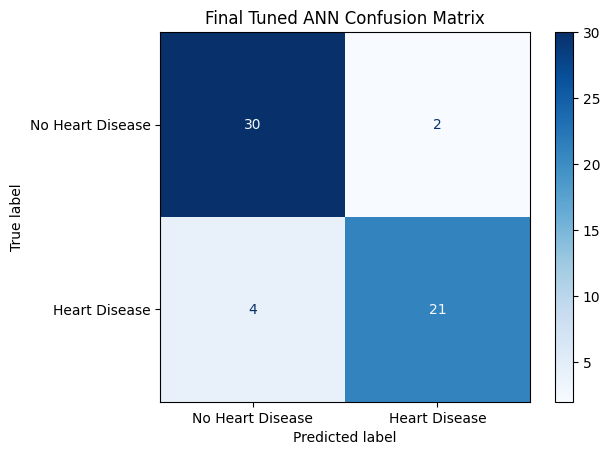

In [126]:
cm_ann = confusion_matrix(y_test, y_pred_ann)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_ann,
    display_labels=['No Heart Disease', 'Heart Disease']
)

disp.plot(cmap='Blues')
plt.title("Final Tuned ANN Confusion Matrix")
plt.show()

####Final Tuned ANN Training Curves

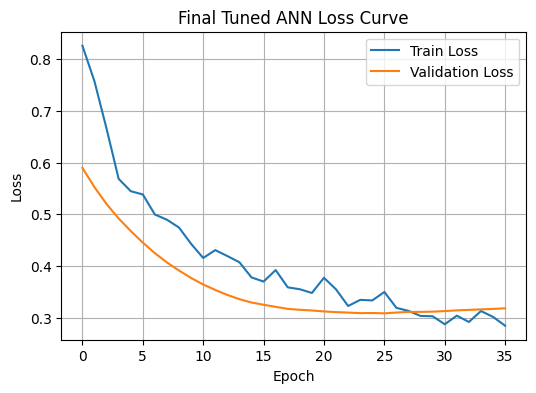

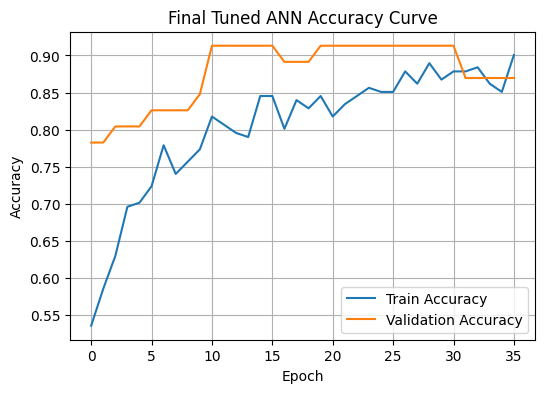

In [127]:
plt.figure(figsize=(6, 4))
plt.plot(best_ann_history.history['loss'], label='Train Loss')
plt.plot(best_ann_history.history['val_loss'], label='Validation Loss')
plt.title("Final Tuned ANN Loss Curve")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(6, 4))
plt.plot(best_ann_history.history['accuracy'], label='Train Accuracy')
plt.plot(best_ann_history.history['val_accuracy'], label='Validation Accuracy')
plt.title("Final Tuned ANN Accuracy Curve")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

####Final Tuned ANN ROC Curve

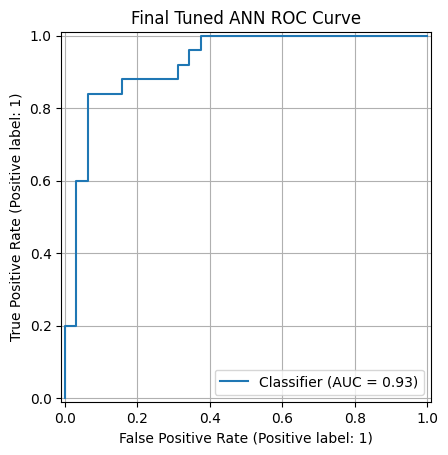

In [128]:
RocCurveDisplay.from_predictions(y_test, y_prob_ann)
plt.title("Final Tuned ANN ROC Curve")
plt.grid(True)
plt.show()

##Comparison of Baseline ANN and Tuned ANN

In [129]:
ann_comparison_df = pd.DataFrame({
    'Baseline ANN': ann_baseline_metrics,
    'Tuned ANN': ann_tuned_metrics
}).T

ann_comparison_df = ann_comparison_df.round(4)

# Select best ANN using all five metrics
ann_comparison_df['Average Rank'] = ann_comparison_df[
    ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC']
].rank(ascending=False).mean(axis=1)

ann_comparison_df = ann_comparison_df.sort_values(by='Average Rank')

display(ann_comparison_df)

best_ann_name = ann_comparison_df.index[0]
final_ann_metrics = ann_comparison_df.loc[best_ann_name].drop('Average Rank').to_dict()


,Accuracy,Precision,Recall,F1-Score,ROC-AUC,Average Rank
Tuned ANN,0.8947,0.913,0.84,0.8750,0.925,1.3
Baseline ANN,0.8772,0.875,0.84,0.8571,0.930,1.7


##Feature Importance of ANN

###ANN Permutation Importance

In [130]:
class ANNWrapper:
    def fit(self, X, y):
        return self

    def predict(self, X):
        probs = best_ann_model.predict(X, verbose=0).ravel()
        return (probs >= 0.5).astype(int)

    def score(self, X, y):
        y_pred = self.predict(X)
        return accuracy_score(y, y_pred)

ann_wrapper = ANNWrapper()

perm_result = permutation_importance(
    ann_wrapper,
    X_test,
    y_test,
    n_repeats=20,
    random_state=42,
    scoring='accuracy'
)

ann_importance = pd.Series(
    perm_result.importances_mean,
    index=X_train.columns
).sort_values(ascending=False)

print("ANN Permutation Importance:")
print(ann_importance)

ANN Permutation Importance:
oldpeak      0.083333
sex_0        0.059649
ca_0         0.059649
thal_1       0.053509
thalach      0.042105
restecg_0    0.035088
chol         0.034211
cp_3         0.028070
slope_0      0.027193
cp_2         0.014912
sex_1        0.013158
exang_0      0.009649
exang_1      0.009649
restecg_2    0.007895
trestbps     0.006140
ï»¿age       0.005263
cp_1         0.004386
fbs_0        0.003509
restecg_1    0.002632
slope_2      0.001754
cp_0         0.000877
thal_2       0.000877
slope_1      0.000000
fbs_1        0.000000
thal_3       0.000000
ca_2         0.000000
ca_1        -0.000877
ca_3        -0.000877
dtype: float64


###Interpretability Plot for ANN

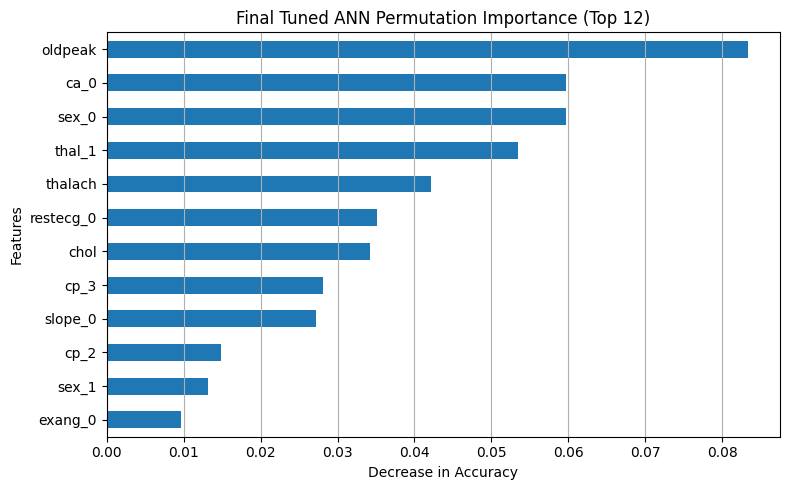

In [131]:
ann_importance.head(12).sort_values().plot(kind='barh', figsize=(8, 5))

plt.title('Final Tuned ANN Permutation Importance (Top 12)')
plt.xlabel('Decrease in Accuracy')
plt.ylabel('Features')
plt.grid(axis='x')
plt.tight_layout()
plt.show()

###Combined Feature Importance Table for All Tree-Based ML Models & ANN

In [132]:
rf_imp = pd.Series(best_models['Random Forest'].feature_importances_, index=X_train.columns)
dt_imp = pd.Series(best_models['Decision Tree'].feature_importances_, index=X_train.columns)
ada_imp = pd.Series(best_models['AdaBoost'].feature_importances_, index=X_train.columns)
xgb_imp = pd.Series(best_models['XGBoost'].feature_importances_, index=X_train.columns)
ann_imp = ann_importance

all_importance_df = pd.DataFrame({
    'Random Forest': rf_imp,
    'Decision Tree': dt_imp,
    'AdaBoost': ada_imp,
    'XGBoost': xgb_imp,
    'ANN (Permutation)': ann_imp
}).fillna(0)

display(all_importance_df.head())

,Random Forest,Decision Tree,AdaBoost,XGBoost,ANN (Permutation)
ca_0,0.082355,0.139753,0.165618,0.069427,0.059649
ca_1,0.018334,0.000000,0.000000,0.042166,-0.000877
ca_2,0.007482,0.000000,0.000000,0.000000,0.000000
ca_3,0.004715,0.000000,0.000000,0.000000,-0.000877
chol,0.029531,0.000000,0.016289,0.031278,0.034211


###Selecting Top Overall Features for Comparison

In [133]:
top_n = 12

top_features = (
    all_importance_df.mean(axis=1)
    .sort_values(ascending=False)
    .head(top_n)
    .index
)

importance_top_df = all_importance_df.loc[top_features]

display(importance_top_df)

,Random Forest,Decision Tree,AdaBoost,XGBoost,ANN (Permutation)
cp_3,0.133936,0.435198,0.240955,0.174380,0.028070
thal_3,0.123543,0.238288,0.152461,0.107600,0.000000
ca_0,0.082355,0.139753,0.165618,0.069427,0.059649
oldpeak,0.068739,0.071269,0.187902,0.060553,0.083333
thal_1,0.129639,0.000000,0.076295,0.185330,0.053509
thalach,0.084744,0.069482,0.096308,0.037369,0.042105
exang_1,0.068446,0.000000,0.027660,0.034181,0.009649
exang_0,0.061219,0.000000,0.019397,0.042993,0.009649
sex_0,0.016803,0.000000,0.017113,0.030898,0.059649
ï»¿age,0.030354,0.046009,0.000000,0.037744,0.005263


###Compare Feature Importance Across Tree-Based ML Models & ANN

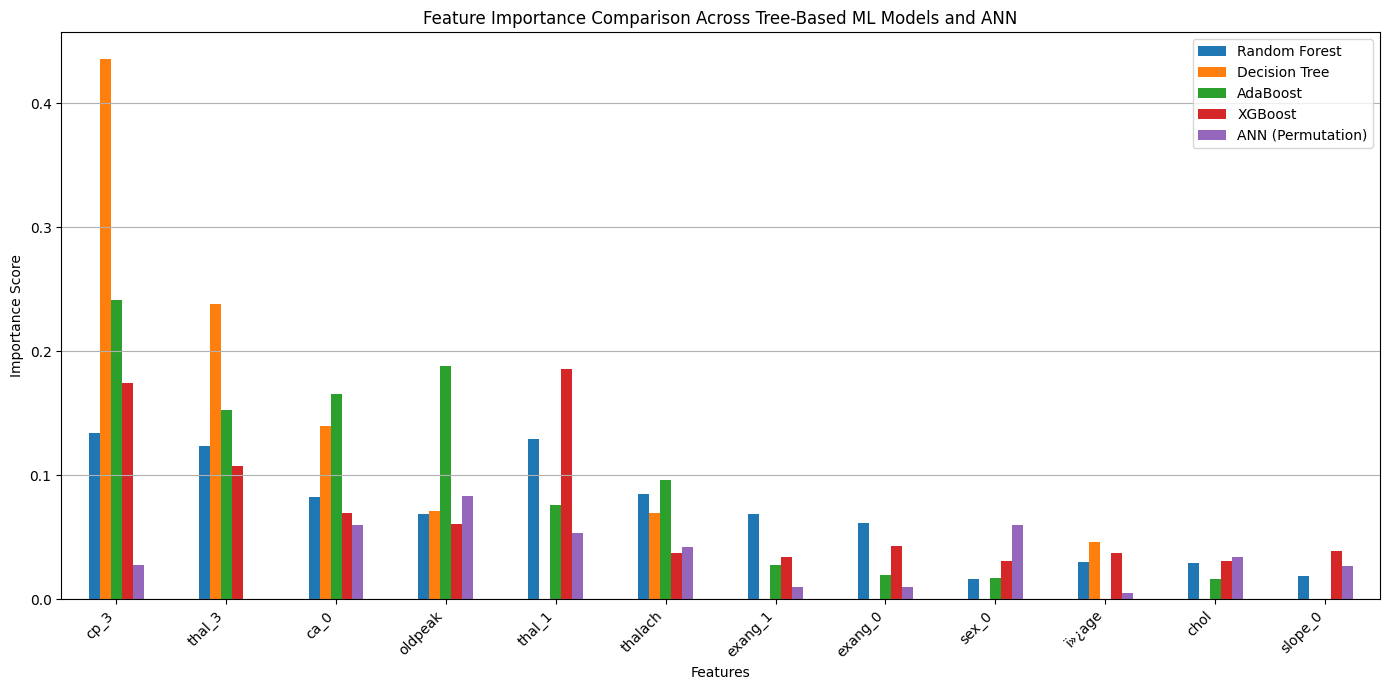

In [134]:
importance_top_df.plot(kind='bar', figsize=(14, 7))

plt.title('Feature Importance Comparison Across Tree-Based ML Models and ANN')
plt.xlabel('Features')
plt.ylabel('Importance Score')
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y')
plt.legend()
plt.tight_layout()
plt.show()

#Overll Model Comparison

##Collect All Model Metrics of Tuned ML Models & Final Tuned ANN Together

In [135]:
model_metrics = {}

# Tuned Logistic Regression
y_pred_lr = best_models['Logistic Regression'].predict(X_test)
y_prob_lr = best_models['Logistic Regression'].predict_proba(X_test)[:, 1]
model_metrics['Logistic Regression'] = {
    'Accuracy': accuracy_score(y_test, y_pred_lr),
    'Precision': precision_score(y_test, y_pred_lr, zero_division=0),
    'Recall': recall_score(y_test, y_pred_lr, zero_division=0),
    'F1-Score': f1_score(y_test, y_pred_lr, zero_division=0),
    'ROC-AUC': roc_auc_score(y_test, y_prob_lr)
}

# Tuned Random Forest
y_pred_rf = best_models['Random Forest'].predict(X_test)
y_prob_rf = best_models['Random Forest'].predict_proba(X_test)[:, 1]
model_metrics['Random Forest'] = {
    'Accuracy': accuracy_score(y_test, y_pred_rf),
    'Precision': precision_score(y_test, y_pred_rf, zero_division=0),
    'Recall': recall_score(y_test, y_pred_rf, zero_division=0),
    'F1-Score': f1_score(y_test, y_pred_rf, zero_division=0),
    'ROC-AUC': roc_auc_score(y_test, y_prob_rf)
}

# Tuned SVM
y_pred_svm = best_models['Support Vector Machine'].predict(X_test)
y_prob_svm = best_models['Support Vector Machine'].predict_proba(X_test)[:, 1]
model_metrics['SVM'] = {
    'Accuracy': accuracy_score(y_test, y_pred_svm),
    'Precision': precision_score(y_test, y_pred_svm, zero_division=0),
    'Recall': recall_score(y_test, y_pred_svm, zero_division=0),
    'F1-Score': f1_score(y_test, y_pred_svm, zero_division=0),
    'ROC-AUC': roc_auc_score(y_test, y_prob_svm)
}

# Tuned Decision Tree
y_pred_dt = best_models['Decision Tree'].predict(X_test)
y_prob_dt = best_models['Decision Tree'].predict_proba(X_test)[:, 1]
model_metrics['Decision Tree'] = {
    'Accuracy': accuracy_score(y_test, y_pred_dt),
    'Precision': precision_score(y_test, y_pred_dt, zero_division=0),
    'Recall': recall_score(y_test, y_pred_dt, zero_division=0),
    'F1-Score': f1_score(y_test, y_pred_dt, zero_division=0),
    'ROC-AUC': roc_auc_score(y_test, y_prob_dt)
}

# Tuned AdaBoost
y_pred_ada = best_models['AdaBoost'].predict(X_test)
y_prob_ada = best_models['AdaBoost'].predict_proba(X_test)[:, 1]
model_metrics['AdaBoost'] = {
    'Accuracy': accuracy_score(y_test, y_pred_ada),
    'Precision': precision_score(y_test, y_pred_ada, zero_division=0),
    'Recall': recall_score(y_test, y_pred_ada, zero_division=0),
    'F1-Score': f1_score(y_test, y_pred_ada, zero_division=0),
    'ROC-AUC': roc_auc_score(y_test, y_prob_ada)
}

# Tuned XGBoost
y_pred_xgb = best_models['XGBoost'].predict(X_test)
y_prob_xgb = best_models['XGBoost'].predict_proba(X_test)[:, 1]
model_metrics['XGBoost'] = {
    'Accuracy': accuracy_score(y_test, y_pred_xgb),
    'Precision': precision_score(y_test, y_pred_xgb, zero_division=0),
    'Recall': recall_score(y_test, y_pred_xgb, zero_division=0),
    'F1-Score': f1_score(y_test, y_pred_xgb, zero_division=0),
    'ROC-AUC': roc_auc_score(y_test, y_prob_xgb)
}

# Final Tuned ANN
model_metrics['ANN'] = {
    'Accuracy': accuracy_ann,
    'Precision': precision_ann,
    'Recall': recall_ann,
    'F1-Score': f1_ann,
    'ROC-AUC': roc_auc_ann
}

metrics_df = pd.DataFrame(model_metrics).T
metrics_df = metrics_df.round(4)

display(metrics_df)

,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Logistic Regression,0.8947,0.9130,0.84,0.8750,0.9325
Random Forest,0.8421,0.8636,0.76,0.8085,0.9138
SVM,0.8772,0.8750,0.84,0.8571,0.9275
Decision Tree,0.7368,0.7083,0.68,0.6939,0.7950
AdaBoost,0.7895,0.7826,0.72,0.7500,0.9081
XGBoost,0.7895,0.7826,0.72,0.7500,0.8888
ANN,0.8947,0.9130,0.84,0.8750,0.9250


##Comparison Bar Chart Across Tuned ML Models & Final Tuned ANN

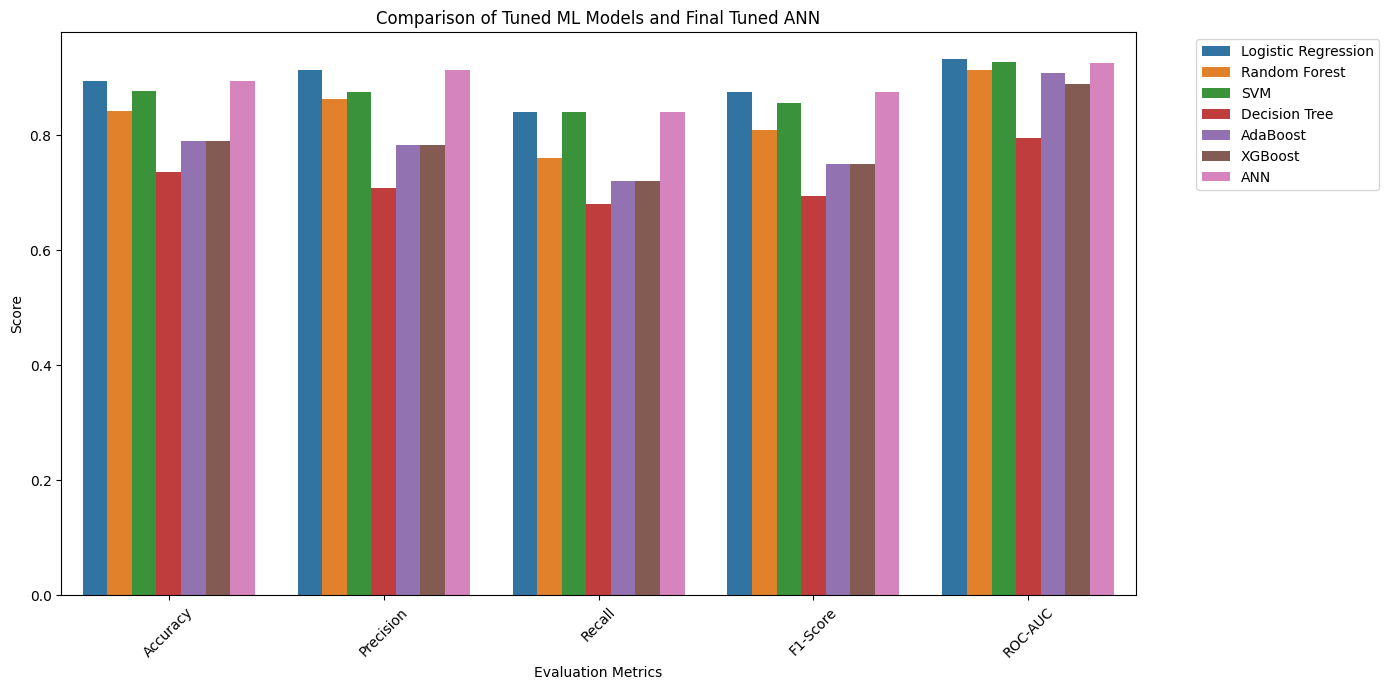

In [136]:
plt.figure(figsize=(14, 7))

metrics_melted = metrics_df.reset_index().rename(columns={'index': 'Model'})
metrics_melted = metrics_melted.melt(
    id_vars='Model',
    var_name='Metric',
    value_name='Score'
)

sns.barplot(data=metrics_melted, x='Metric', y='Score', hue='Model')

plt.title('Comparison of Tuned ML Models and Final Tuned ANN')
plt.xlabel('Evaluation Metrics')
plt.ylabel('Score')
plt.xticks(rotation=45)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

##ROC Comparison of Tuned ML Models & Final Tuned ANN

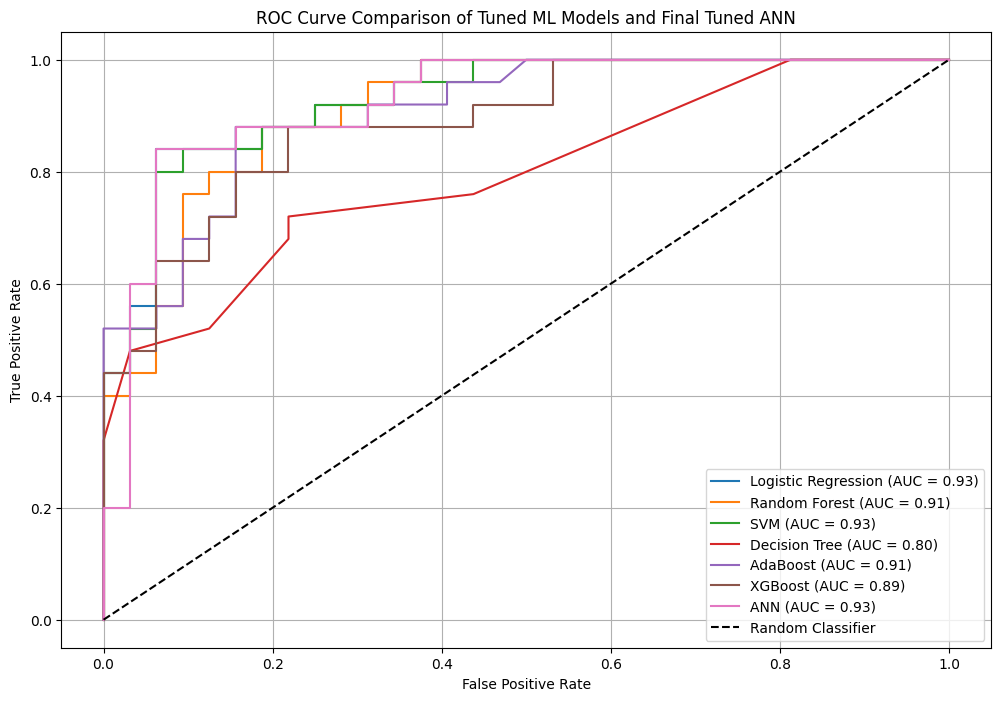

In [137]:
plt.figure(figsize=(12, 8))

models_for_roc = {
    'Logistic Regression': y_prob_lr,
    'Random Forest': y_prob_rf,
    'SVM': y_prob_svm,
    'Decision Tree': y_prob_dt,
    'AdaBoost': y_prob_ada,
    'XGBoost': y_prob_xgb,
    'ANN': y_prob_ann
}

for name, y_score in models_for_roc.items():
    fpr, tpr, _ = roc_curve(y_test, y_score)
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f'{name} (AUC = {roc_auc:.2f})')

plt.plot([0, 1], [0, 1], 'k--', label='Random Classifier')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve Comparison of Tuned ML Models and Final Tuned ANN')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

##Best Model Summary

In [138]:
ranked_models = metrics_df.copy()

# Final ranking treats all five evaluation metrics as primary metrics
ranked_models['Average Rank'] = ranked_models[
    ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC']
].rank(ascending=False).mean(axis=1)

ranked_models = ranked_models.sort_values(by='Average Rank')

display(ranked_models)

best_overall_model = ranked_models.index[0]

print("Best Overall Model Considering All Five Metrics:", best_overall_model)

print("\nBest Model Performance:")
display(metrics_df.loc[[best_overall_model]])

,Accuracy,Precision,Recall,F1-Score,ROC-AUC,Average Rank
Logistic Regression,0.8947,0.9130,0.84,0.8750,0.9325,1.5
ANN,0.8947,0.9130,0.84,0.8750,0.9250,1.9
SVM,0.8772,0.8750,0.84,0.8571,0.9275,2.6
Random Forest,0.8421,0.8636,0.76,0.8085,0.9138,4.0
AdaBoost,0.7895,0.7826,0.72,0.7500,0.9081,5.4
XGBoost,0.7895,0.7826,0.72,0.7500,0.8888,5.6
Decision Tree,0.7368,0.7083,0.68,0.6939,0.7950,7.0


Best Overall Model Considering All Five Metrics: Logistic Regression

Best Model Performance:


,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Logistic Regression,0.8947,0.913,0.84,0.875,0.9325
